# SoCal XCache: Structured TCN Residual Correction
### Week 10 | Yingxin Deng | 2026-11-11

Can a small residual Ridge model improve next-day daily **hit_size RMSE (TB)** while retaining the relationship `access = hit + miss`?

This notebook runs residual diagnostics, ratio-residual Ridge, direct residual Ridge, and a compact hourly-shape feature comparison. All model code is contained in this notebook.

## 1. Protocol and evaluation

Use the complete SoCal period, 2020-05-31 through 2024-03-31, with chronological **60% TCN train / 10% TCN validation / 15% Ridge calibration / remaining 15% test**.

- Base model: 28-day lookback, five residual blocks, 64 hidden channels per block, kernel size 3, dilations 1, 2, 4, 8, 16.
- Inputs: all six historical daily variables, transformed with log1p and training-only standardization.
- Outputs: standardized log-access for count/size plus sigmoid hit ratios. The decoder reconstructs all six predictions.
- TCN checkpoint selection: validation **hit_size RMSE in TB**.
- Ridge alpha and correction-method selection: three expanding folds inside calibration, scored by corrected **hit_size RMSE in TB**. Include zero correction as an explicit candidate.
- Fixed weights forecast one day at a time. Actual traffic through day t-1 is available when predicting day t. Target-day traffic never enters a feature.
- The test period overlaps earlier project experiments. It is excluded from fitting and selection in this experiment, but is a reused benchmark rather than a new prospectively untouched test.
- Count variables and the Structured TCN training loss remain part of the model. Choosing hit_size RMSE for early stopping does not change the training loss into a single-target loss.

In [1]:
from pathlib import Path
import os
import json
import copy
import random
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from scipy.special import expit, logit
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'xcache-ts-df' / 'socal-2006-2403-daily-ml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the xcache project or one of its week folders.')
OUTPUT_DIR = ROOT / 'week10' / 'results' / 'whole_range_residual_ridge'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
SIZE_NAMES = ['access_size', 'hit_size', 'miss_size']
PRIMARY_INDEX = FEATURE_NAMES.index('hit_size')
LOOKBACK, SEED = 28, 42
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
RATIO_EPSILON = 1e-4
ALPHAS = [1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0, 100.0, 1000.0]
N_CV_SPLITS = 3
USE_CACHED_TCN = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
CONFIG = dict(lookback=LOOKBACK, seed=SEED, channels=list(CHANNELS),
              kernel_size=KERNEL_SIZE, dropout=DROPOUT, max_epochs=MAX_EPOCHS,
              patience=PATIENCE, batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
              ratio_epsilon=RATIO_EPSILON, primary_metric='hit_size_rmse_tb')

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=str), encoding='utf-8')

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(predicted) - np.asarray(actual)) ** 2)))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Explicit list conversion avoids the Tensor/NumPy ABI bridge in older PyTorch builds.
def tensor_from_array(values, on_device=None):
    return torch.tensor(np.asarray(values).tolist(), dtype=torch.float32,
                        device=on_device)

save_json(OUTPUT_DIR / 'environment.json',
          dict(python=platform.python_version(), numpy=np.__version__,
               pandas=pd.__version__, torch=torch.__version__, device=str(device)))
print('Output directory:', OUTPUT_DIR)
print('Device:', device)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

Output directory: /Users/dengyingxin/Desktop/xcache/week10/results/whole_range_residual_ridge
Device: cpu


In [2]:
daily = pd.read_pickle(ROOT / 'xcache-ts-df' / 'socal-2006-2403-daily-ml')
daily = daily.loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
daily[SIZE_NAMES] /= 1000 ** 4
hourly = pd.read_pickle(ROOT / 'xcache-ts-df' / 'socal-2006-2403-hourly-ml')
hourly = hourly.loc['2020-05-31':'2024-03-31', FEATURE_NAMES].sort_index().copy()
hourly[SIZE_NAMES] /= 1000 ** 4
assert daily.index.equals(pd.date_range('2020-05-31', '2024-03-31'))
assert hourly.index.is_unique
assert np.isfinite(daily.to_numpy()).all() and (daily >= 0).all().all()
np.testing.assert_allclose(daily.access_count, daily.hit_count + daily.miss_count)
np.testing.assert_allclose(daily.access_size, daily.hit_size + daily.miss_size)

n = len(daily)
n_train, n_validation, n_calibration = int(.60 * n), int(.10 * n), int(.15 * n)
bounds = [0, n_train, n_train + n_validation, n_train + n_validation + n_calibration, n]
SPLITS = {name: np.arange(left, right) for name, left, right in
          zip(['train', 'validation', 'calibration', 'test'], bounds[:-1], bounds[1:])}
split_table = pd.DataFrame([
    dict(subset=name, first_day=daily.index[pos[0]].date(),
         last_day=daily.index[pos[-1]].date(), raw_days=len(pos))
    for name, pos in SPLITS.items()
])
split_table.to_csv(OUTPUT_DIR / 'chronological_split.csv', index=False)
display(split_table)
RAW = daily.to_numpy(dtype=np.float64)
save_json(OUTPUT_DIR / 'experiment_config.json', CONFIG)

,subset,first_day,last_day,raw_days
0,train,2020-05-31,2022-09-17,840
1,validation,2022-09-18,2023-02-04,140
2,calibration,2023-02-05,2023-09-02,210
3,test,2023-09-03,2024-03-31,211


## 2. Causal daily features and compact intraday shape features

The Ridge feature vector has seven columns: predicted log-access-size, predicted size-ratio logit, log hit-size at lags 1 and 7, log MA(7), log MA(28), and the slope over the preceding seven days.

The compact TCN adds high/mean, low/mean, and range/mean for historical **access_size and hit_size**, giving six additional inputs. These describe intraday concentration rather than repeating the daily total. Range/mean is exactly high/mean minus low/mean, so these six descriptors are not six independent signals.

Only complete days with 24 distinct, valid hourly records supply shape features. Zero-traffic days receive zero-valued shape features. Every daily input window stops before its target date. Both TCNs use the same eligible target dates.

In [3]:
def build_compact_shapes(hourly_frame, index):
    groups = hourly_frame.groupby(hourly_frame.index.normalize())
    coverage = groups.size().reindex(index)
    distinct_hours = hourly_frame.index.to_series().groupby(
        hourly_frame.index.normalize()).nunique().reindex(index)
    complete = coverage.eq(24) & distinct_hours.eq(24)
    shape = pd.DataFrame(index=index)
    for name in ['access_size', 'hit_size']:
        grouped = hourly_frame[name].groupby(hourly_frame.index.normalize())
        high = grouped.max().reindex(index)
        low = grouped.min().reindex(index)
        mean = grouped.mean().reindex(index)
        valid = grouped.count().reindex(index).eq(24) & complete
        # Exact divide for positive means; zero-total days have no within-day traffic.
        shape[f'{name}_high_over_mean'] = np.divide(
            high, mean, out=np.zeros(len(index)), where=mean > 0)
        shape[f'{name}_low_over_mean'] = np.divide(
            low, mean, out=np.zeros(len(index)), where=mean > 0)
        shape[f'{name}_range_over_mean'] = shape[f'{name}_high_over_mean'] - shape[f'{name}_low_over_mean']
        shape.loc[~valid, [f'{name}_{suffix}' for suffix in
                          ['high_over_mean', 'low_over_mean', 'range_over_mean']]] = np.nan
    return shape, coverage

def trailing_slope(values):
    x = np.arange(len(values), dtype=float)
    centered = x - x.mean()
    return float(np.dot(centered, values) / np.dot(centered, centered))

shapes, coverage = build_compact_shapes(hourly, daily.index)
SHAPE_NAMES = list(shapes.columns)
shape_values = shapes.to_numpy()
missing = ~np.isfinite(shape_values).all(axis=1)
prefix_missing = np.concatenate([[0], np.cumsum(missing)])
eligible = np.asarray([p for p in range(LOOKBACK, n)
                       if prefix_missing[p] == prefix_missing[p - LOOKBACK]], dtype=int)
TARGETS = {name: np.intersect1d(pos, eligible) for name, pos in SPLITS.items()}
split_table['eligible_targets'] = [len(TARGETS[name]) for name in SPLITS]
split_table.to_csv(OUTPUT_DIR / 'chronological_split.csv', index=False)

DAILY_CAUSAL = pd.DataFrame(index=daily.index)
DAILY_CAUSAL['log_hit_size_lag1'] = np.log1p(daily.hit_size.shift(1))
DAILY_CAUSAL['log_hit_size_lag7'] = np.log1p(daily.hit_size.shift(7))
DAILY_CAUSAL['log_hit_size_ma7'] = np.log1p(daily.hit_size.shift(1).rolling(7).mean())
DAILY_CAUSAL['log_hit_size_ma28'] = np.log1p(daily.hit_size.shift(1).rolling(28).mean())
DAILY_CAUSAL['hit_size_slope7'] = daily.hit_size.shift(1).rolling(7).apply(trailing_slope, raw=True)

# The hourly daily sum must agree with the daily source on complete days.
hourly_sum = hourly[SIZE_NAMES].groupby(hourly.index.normalize()).sum().reindex(daily.index)
complete_dates = coverage.eq(24)
np.testing.assert_allclose(hourly_sum.loc[complete_dates],
                           daily.loc[complete_dates, SIZE_NAMES], rtol=1e-6, atol=1e-6)
display(split_table)
display(shapes.loc['2023-01-01':'2023-01-05'])
print('Compact TCN input variables:', 6 + len(SHAPE_NAMES))
print('Incomplete hourly days:', list(daily.index[missing].strftime('%Y-%m-%d')))

,subset,first_day,last_day,raw_days,eligible_targets
0,train,2020-05-31,2022-09-17,840,811
1,validation,2022-09-18,2023-02-04,140,140
2,calibration,2023-02-05,2023-09-02,210,210
3,test,2023-09-03,2024-03-31,211,211


,access_size_high_over_mean,access_size_low_over_mean,access_size_range_over_mean,hit_size_high_over_mean,hit_size_low_over_mean,hit_size_range_over_mean
data_start_time_datetime,,,,,,
2023-01-01,2.470862,0.000000,2.470862,2.867241,0.000000,2.867241
2023-01-02,2.084479,0.430142,1.654336,2.109559,0.438765,1.670794
2023-01-03,3.932561,0.073855,3.858706,4.176849,0.069869,4.106980
2023-01-04,2.765024,0.253650,2.511374,2.942941,0.249370,2.693571
2023-01-05,2.017700,0.022657,1.995043,2.074731,0.019340,2.055391


Compact TCN input variables: 12
Incomplete hourly days: ['2020-05-31', '2024-03-31']


## 3. Hard Structured TCN and training functions

The loss remains standardized log-access MSE plus 5 times raw hit-ratio MSE. Early stopping uses validation hit-size RMSE in original TB units. Each model is frozen before generating calibration residuals.

Selected checkpoints and training histories are cached. A completed training run can be reused only when the configuration and input-data signature match.

In [4]:
class Chomp1d(nn.Module):
    def __init__(self, size):
        super().__init__()
        self.size = size
    def forward(self, x):
        return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__()
        padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, KERNEL_SIZE,
                      padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Conv1d(out_channels, out_channels, KERNEL_SIZE,
                      padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))

class StructuredTCN(nn.Module):
    def __init__(self, input_channels):
        super().__init__()
        blocks = []
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(input_channels, out_channels, 2 ** level))
            input_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1], 4)
    def forward(self, x):
        out = self.output(self.tcn(x)[:, :, -1])
        return torch.cat([out[:, :2], torch.sigmoid(out[:, 2:])], dim=1)

def structured_loss(prediction, target):
    return (nn.functional.mse_loss(prediction[:, :2], target[:, :2])
            + 5 * nn.functional.mse_loss(prediction[:, 2:], target[:, 2:]))

def prepare_family(use_shapes):
    values = np.log1p(RAW)
    input_names = [f'log1p_{name}' for name in FEATURE_NAMES]
    if use_shapes:
        values = np.column_stack([values, shape_values])
        input_names += SHAPE_NAMES
    # Use common complete-day rows for comparable daily-channel scaling.
    scaler_positions = SPLITS['train'][~missing[SPLITS['train']]]
    input_scaler = StandardScaler().fit(values[scaler_positions])
    scaled = input_scaler.transform(values).astype(np.float32)
    log_access = np.log1p(RAW[:, :2])
    access_scaler = StandardScaler().fit(log_access[SPLITS['train']])
    ratios = np.divide(RAW[:, 2:4], RAW[:, :2],
                       out=np.zeros((n, 2)), where=RAW[:, :2] > 0)
    labels = np.column_stack([access_scaler.transform(log_access), ratios]).astype(np.float32)
    sequences = {part: np.stack([scaled[p - LOOKBACK:p] for p in positions])
                 for part, positions in TARGETS.items()}
    assert all(np.isfinite(x).all() for x in sequences.values())
    return dict(x=sequences, y={part: labels[pos] for part, pos in TARGETS.items()},
                input_scaler=input_scaler, access_scaler=access_scaler,
                input_names=input_names, use_shapes=use_shapes)

def decode(model, features, access_scaler):
    model.eval()
    rows = []
    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            batch = tensor_from_array(
                features[start:start + BATCH_SIZE].transpose(0, 2, 1), device)
            rows.extend(model(batch).cpu().tolist())
    output = np.asarray(rows, dtype=float)
    access = np.maximum(np.expm1(access_scaler.inverse_transform(output[:, :2])), 0)
    ratio = output[:, 2:]
    prediction = np.column_stack([access, access * ratio, access * (1 - ratio)])
    assert np.isfinite(prediction).all()
    return prediction

def train_family(family_name, use_shapes, seed=None, run_output_dir=None):
    run_seed = SEED if seed is None else int(seed)
    prepared = prepare_family(use_shapes)
    folder = (OUTPUT_DIR if run_output_dir is None else Path(run_output_dir)) / family_name
    folder.mkdir(parents=True, exist_ok=True)
    signature = hashlib.sha256(
        json.dumps(dict(config=dict(CONFIG, seed=run_seed), inputs=prepared['input_names']), sort_keys=True).encode()
        + RAW.tobytes() + (shape_values.tobytes() if use_shapes else b'')
    ).hexdigest()
    set_seed(run_seed)
    model = StructuredTCN(len(prepared['input_names'])).to(device)
    checkpoint_path = folder / 'selected_checkpoint.pt'
    metadata_path = folder / 'training_metadata.json'
    cached = (USE_CACHED_TCN and checkpoint_path.exists() and metadata_path.exists()
              and json.loads(metadata_path.read_text()).get('signature') == signature)
    if cached:
        metadata = json.loads(metadata_path.read_text())
        model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
        history = pd.read_csv(folder / 'training_history.csv')
        print(f"{family_name}: restored epoch {metadata['best_epoch']} checkpoint", flush=True)
    else:
        loader = DataLoader(TensorDataset(
            tensor_from_array(prepared['x']['train'].transpose(0, 2, 1)),
            tensor_from_array(prepared['y']['train'])),
            batch_size=BATCH_SIZE, shuffle=True)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        best, best_epoch, state, stale = np.inf, 0, None, 0
        history_rows = []
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            total, observations = 0., 0
            for xb, yb in loader:
                optimizer.zero_grad()
                loss = structured_loss(model(xb.to(device)), yb.to(device))
                if not torch.isfinite(loss):
                    raise RuntimeError('Non-finite TCN loss.')
                loss.backward()
                optimizer.step()
                total += float(loss.item()) * len(xb)
                observations += len(xb)
            forecast = decode(model, prepared['x']['validation'], prepared['access_scaler'])
            score = rmse(RAW[TARGETS['validation'], PRIMARY_INDEX], forecast[:, PRIMARY_INDEX])
            history_rows.append(dict(epoch=epoch, training_structured_loss=total / observations,
                                     validation_hit_size_rmse=score))
            if score < best:
                best, best_epoch, state, stale = score, epoch, copy.deepcopy(model.state_dict()), 0
            else:
                stale += 1
            print(f'{family_name}: epoch {epoch:02d}, validation hit_size RMSE = {score:.4f} TB', flush=True)
            if stale >= PATIENCE:
                break
        model.load_state_dict(state)
        history = pd.DataFrame(history_rows)
        history.to_csv(folder / 'training_history.csv', index=False)
        torch.save({key: value.cpu() for key, value in state.items()}, checkpoint_path)
        metadata = dict(signature=signature, best_epoch=best_epoch,
                        validation_hit_size_rmse=best, input_names=prepared['input_names'],
                        parameter_count=sum(p.numel() for p in model.parameters()))
        save_json(metadata_path, metadata)
    bundle = dict(family=family_name, model=model, prepared=prepared,
                  metadata=metadata, history=history, forecasts={})
    for part in ['validation', 'calibration', 'test']:
        bundle['forecasts'][part] = decode(
            model, prepared['x'][part], prepared['access_scaler'])
        # Persist frozen forecasts so later Ridge sections can run without loading PyTorch.
        forecast_table = pd.DataFrame(bundle['forecasts'][part],
            index=daily.index[TARGETS[part]], columns=FEATURE_NAMES)
        forecast_table.to_csv(folder / f'{part}_frozen_forecasts.csv', index_label='target_date')
    print(f"{family_name}: selected epoch {metadata['best_epoch']}, "
          f"validation RMSE {metadata['validation_hit_size_rmse']:.4f} TB", flush=True)
    return bundle

In [5]:
base = train_family('daily_base', use_shapes=False)

daily_base: restored epoch 7 checkpoint


daily_base: selected epoch 7, validation RMSE 18.0895 TB


## 4. Calibration-only hit-size residual diagnostics

Define residual as actual minus forecast, so a positive residual means underprediction. Inspect both TB and log1p residuals, autocorrelation through lag 28, causal-feature associations, and errors on normal/peak/spike days. Peak and spike groups may overlap.

The ratio correction has an important ceiling: with access held fixed and ratio between zero and one, corrected hit-size cannot exceed predicted access-size. A logit-residual model is therefore a constrained candidate, not a guaranteed improvement.

,category,days,rmse_tb,prediction_bias_tb
0,Overall,210,37.5083,-14.8553
1,Normal,95,10.9969,5.1839
2,Peak,108,51.1565,-32.5908
3,Spike,62,60.4389,-45.7330


,feature,residual_tb_correlation,residual_log_correlation
0,predicted_log_access_size,0.1828,0.0042
1,predicted_size_ratio_logit,0.1781,0.0476
2,log_hit_size_lag1,0.2360,0.0605
3,log_hit_size_lag7,0.1362,0.0644
4,log_hit_size_ma7,0.2363,0.1015
5,log_hit_size_ma28,0.0887,0.0217
6,hit_size_slope7,0.0554,-0.0215


Calibration days with actual hit_size above predicted access_size: 113 / 210
Autocorrelation is descriptive; chronological CV will test whether correction helps.


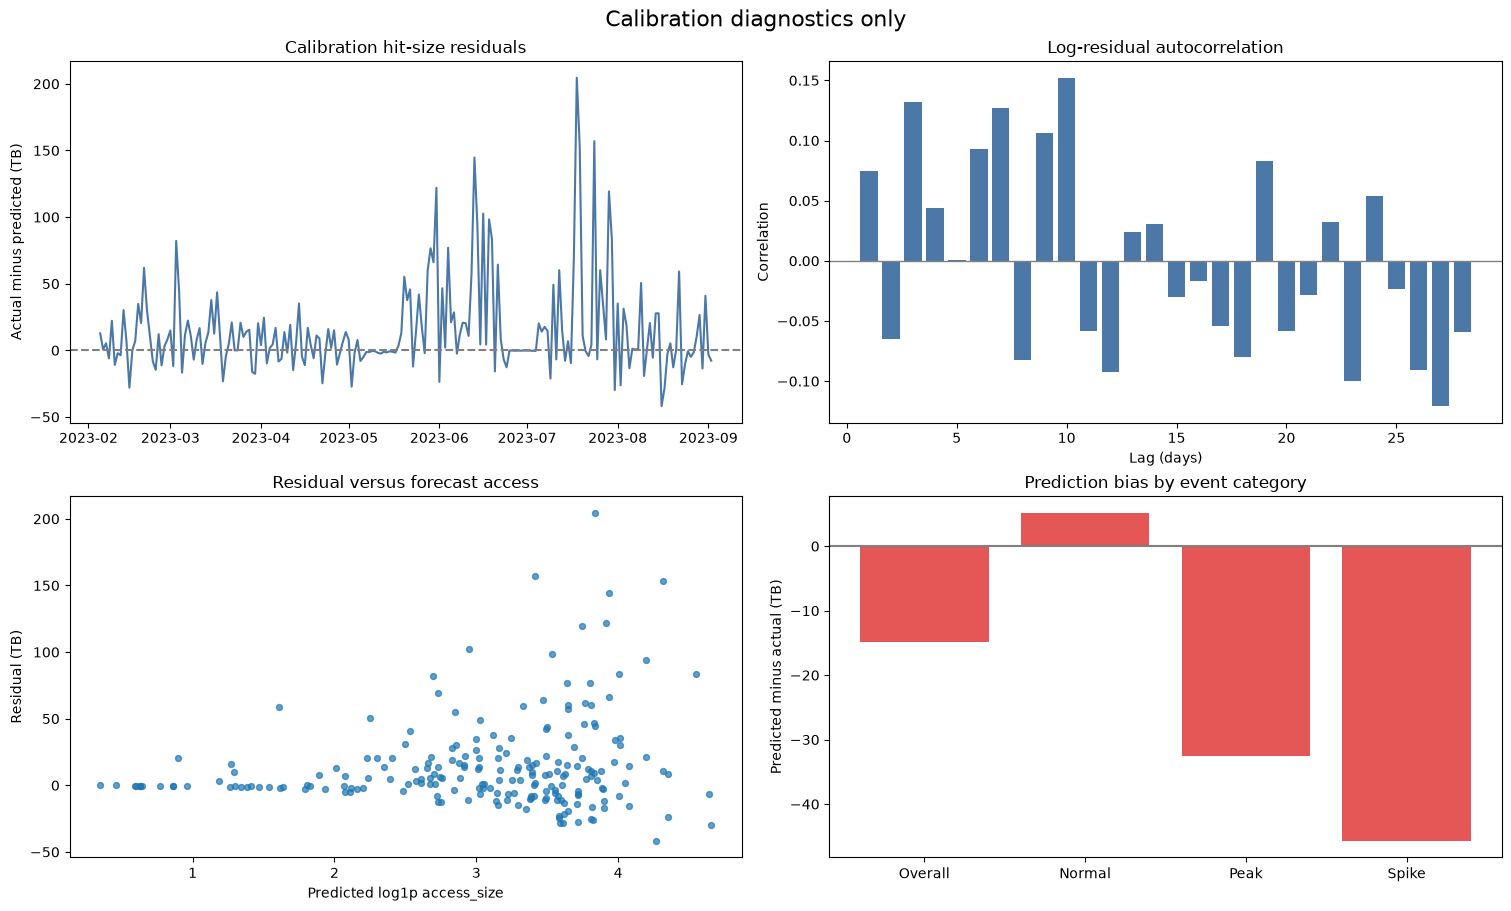

In [6]:
def ridge_features(bundle, part):
    positions = TARGETS[part]
    forecast = bundle['forecasts'][part]
    ratio = np.divide(forecast[:, 3], forecast[:, 1],
                      out=np.zeros(len(positions)), where=forecast[:, 1] > 0)
    table = pd.DataFrame(index=daily.index[positions])
    table['predicted_log_access_size'] = np.log1p(forecast[:, 1])
    table['predicted_size_ratio_logit'] = logit(np.clip(ratio, RATIO_EPSILON, 1 - RATIO_EPSILON))
    for name in DAILY_CAUSAL:
        table[name] = DAILY_CAUSAL[name].iloc[positions].to_numpy()
    assert np.isfinite(table.to_numpy()).all()
    return table

train_hit_size = RAW[SPLITS['train'], PRIMARY_INDEX]
PEAK_THRESHOLD = float(np.quantile(train_hit_size, .90))
SPIKE_THRESHOLD = float(np.quantile(np.diff(train_hit_size), .90))

def event_masks(positions):
    actual = RAW[positions, PRIMARY_INDEX]
    previous = RAW[positions - 1, PRIMARY_INDEX]
    peak = actual >= PEAK_THRESHOLD
    spike = (actual - previous) >= SPIKE_THRESHOLD
    return dict(Overall=np.ones(len(positions), dtype=bool),
                Normal=~(peak | spike), Peak=peak, Spike=spike)

cal_positions = TARGETS['calibration']
cal_actual = RAW[cal_positions, PRIMARY_INDEX]
cal_prediction = base['forecasts']['calibration'][:, PRIMARY_INDEX]
cal_features = ridge_features(base, 'calibration')
diagnostics = cal_features.copy()
diagnostics['actual_hit_size'] = cal_actual
diagnostics['predicted_hit_size'] = cal_prediction
diagnostics['residual_tb'] = cal_actual - cal_prediction
diagnostics['residual_log1p'] = np.log1p(cal_actual) - np.log1p(cal_prediction)
diagnostics['hit_above_predicted_access'] = cal_actual > base['forecasts']['calibration'][:, 1]
diagnostics.to_csv(OUTPUT_DIR / 'calibration_hit_size_residuals.csv', index_label='target_date')
autocorrelation = pd.DataFrame([
    dict(lag=lag, tb_autocorrelation=diagnostics.residual_tb.autocorr(lag),
         log_autocorrelation=diagnostics.residual_log1p.autocorr(lag))
    for lag in range(1, 29)
])
autocorrelation.to_csv(OUTPUT_DIR / 'calibration_residual_autocorrelation.csv', index=False)
correlation = pd.DataFrame([
    dict(feature=name, residual_tb_correlation=diagnostics[name].corr(diagnostics.residual_tb),
         residual_log_correlation=diagnostics[name].corr(diagnostics.residual_log1p))
    for name in cal_features
])
correlation.to_csv(OUTPUT_DIR / 'calibration_residual_feature_correlations.csv', index=False)

diagnostic_rows = []
for category, mask in event_masks(cal_positions).items():
    error = cal_prediction[mask] - cal_actual[mask]
    diagnostic_rows.append(dict(category=category, days=int(mask.sum()),
        rmse_tb=rmse(cal_actual[mask], cal_prediction[mask]) if mask.any() else np.nan,
        prediction_bias_tb=float(error.mean()) if mask.any() else np.nan))
category_diagnostics = pd.DataFrame(diagnostic_rows)
category_diagnostics.to_csv(OUTPUT_DIR / 'calibration_residual_by_event.csv', index=False)
display(category_diagnostics.round(4))
display(correlation.round(4))
print('Calibration days with actual hit_size above predicted access_size:',
      int(diagnostics.hit_above_predicted_access.sum()), '/', len(diagnostics))
print('Autocorrelation is descriptive; chronological CV will test whether correction helps.')

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
axes[0, 0].plot(diagnostics.index, diagnostics.residual_tb, color='#4c78a8')
axes[0, 0].axhline(0, color='gray', linestyle='--')
axes[0, 0].set(title='Calibration hit-size residuals', ylabel='Actual minus predicted (TB)')
axes[0, 1].bar(autocorrelation.lag, autocorrelation.log_autocorrelation, color='#4c78a8')
axes[0, 1].axhline(0, color='gray', linewidth=1)
axes[0, 1].set(title='Log-residual autocorrelation', xlabel='Lag (days)', ylabel='Correlation')
axes[1, 0].scatter(cal_features.predicted_log_access_size, diagnostics.residual_tb, alpha=.7, s=18)
axes[1, 0].set(title='Residual versus forecast access', xlabel='Predicted log1p access_size', ylabel='Residual (TB)')
axes[1, 1].bar(category_diagnostics.category, category_diagnostics.prediction_bias_tb, color='#e45756')
axes[1, 1].axhline(0, color='gray')
axes[1, 1].set(title='Prediction bias by event category', ylabel='Predicted minus actual (TB)')
fig.suptitle('Calibration diagnostics only', fontsize=16)
fig.savefig(OUTPUT_DIR / 'calibration_residual_diagnostics.png', dpi=180)
plt.show()

## 5. Ratio-residual and direct residual Ridge

Ratio Ridge predicts the residual between actual and forecast **clipped size-ratio logits**, then reconstructs hit/miss at fixed access-size. Days with zero actual access have no identifiable ratio and are excluded from ratio-regression fitting.

Direct Ridge predicts the **log1p hit-size residual** and changes hit-size alone. It is an unconstrained control, not a theoretical upper bound.

For both approaches, the seven causal inputs are identical. Alpha selection uses three chronological calibration folds, with a fresh StandardScaler inside each fold. The score is pooled out-of-fold corrected hit-size RMSE in TB. Zero correction can win. Calibration residuals are out of sample with respect to TCN fitting and checkpoint selection.

In [7]:
def correction_target(bundle, positions):
    actual = RAW[positions]
    forecast = bundle['forecasts']['calibration']
    actual_ratio = np.divide(actual[:, 3], actual[:, 1],
                             out=np.zeros(len(positions)), where=actual[:, 1] > 0)
    predicted_ratio = np.divide(forecast[:, 3], forecast[:, 1],
                                out=np.zeros(len(positions)), where=forecast[:, 1] > 0)
    ratio_target = (logit(np.clip(actual_ratio, RATIO_EPSILON, 1 - RATIO_EPSILON))
                    - logit(np.clip(predicted_ratio, RATIO_EPSILON, 1 - RATIO_EPSILON)))
    return dict(
        ratio=ratio_target,
        direct=np.log1p(actual[:, 3]) - np.log1p(forecast[:, 3]))

def apply_correction(forecast, correction, method):
    corrected = forecast.copy()
    if method == 'ratio':
        r = np.divide(forecast[:, 3], forecast[:, 1],
                      out=np.zeros(len(forecast)), where=forecast[:, 1] > 0)
        z = logit(np.clip(r, RATIO_EPSILON, 1 - RATIO_EPSILON))
        new_ratio = expit(z + correction)
        corrected[:, 3] = forecast[:, 1] * new_ratio
        corrected[:, 5] = forecast[:, 1] * (1 - new_ratio)
    elif method == 'direct':
        corrected[:, 3] = np.maximum(
            np.expm1(np.log1p(forecast[:, 3]) + correction), 0)
    else:
        raise ValueError(method)
    if not np.isfinite(corrected).all():
        raise RuntimeError('Non-finite Ridge prediction.')
    return corrected

def tune_corrections(bundle, run_output_dir=None):
    features = ridge_features(bundle, 'calibration')
    positions = TARGETS['calibration']
    forecast = bundle['forecasts']['calibration']
    actual = RAW[positions, PRIMARY_INDEX]
    targets = correction_target(bundle, positions)
    folds = list(TimeSeriesSplit(n_splits=N_CV_SPLITS).split(features))
    cv_records, fit_records, selected = [], [], {}
    folder = (OUTPUT_DIR if run_output_dir is None else Path(run_output_dir)) / bundle['family']
    folder.mkdir(parents=True, exist_ok=True)
    for method in ['ratio', 'direct']:
        for alpha in [None, *ALPHAS]:
            squared_errors = []
            for fold, (train_indices, valid_indices) in enumerate(folds, 1):
                assert features.index[train_indices].max() < features.index[valid_indices].min()
                if alpha is None:
                    corrected = forecast[valid_indices]
                else:
                    fitting_indices = train_indices
                    if method == 'ratio':
                        fitting_indices = train_indices[RAW[positions[train_indices], 1] > 0]
                    if len(fitting_indices) < 5:
                        raise ValueError('Insufficient identifiable calibration ratios.')
                    pipeline = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
                    pipeline.fit(features.iloc[fitting_indices], targets[method][fitting_indices])
                    delta = pipeline.predict(features.iloc[valid_indices])
                    corrected = apply_correction(forecast[valid_indices], delta, method)
                squared_errors.extend((corrected[:, PRIMARY_INDEX] - actual[valid_indices]) ** 2)
                cv_records.append(dict(family=bundle['family'], method=method,
                    alpha=alpha, correction_enabled=alpha is not None, fold=fold,
                    train_start=features.index[train_indices[0]],
                    train_end=features.index[train_indices[-1]],
                    validation_start=features.index[valid_indices[0]],
                    validation_end=features.index[valid_indices[-1]],
                    validation_days=len(valid_indices),
                    hit_size_rmse_tb=rmse(actual[valid_indices], corrected[:, PRIMARY_INDEX])))
            fit_records.append(dict(family=bundle['family'], method=method, alpha=alpha,
                correction_enabled=alpha is not None,
                calibration_cv_hit_size_rmse=float(np.sqrt(np.mean(squared_errors)))))
        method_rows = [row for row in fit_records if row['method'] == method]
        winner = min(method_rows, key=lambda row: row['calibration_cv_hit_size_rmse'])
        pipeline = None
        if winner['correction_enabled']:
            fit_mask = (RAW[positions, 1] > 0) if method == 'ratio' else np.ones(len(positions), dtype=bool)
            pipeline = make_pipeline(StandardScaler(), Ridge(alpha=winner['alpha']))
            pipeline.fit(features.loc[fit_mask], targets[method][fit_mask])
            # Standardized coefficients provide a compact descriptive audit.
            pd.DataFrame(dict(feature=features.columns,
                              coefficient=pipeline.named_steps['ridge'].coef_)).to_csv(
                folder / f'{method}_ridge_coefficients.csv', index=False)
        selected[method] = dict(**winner, pipeline=pipeline)
    pd.DataFrame(cv_records).to_csv(folder / 'ridge_chronological_cv_folds.csv', index=False)
    pd.DataFrame(fit_records).to_csv(folder / 'ridge_alpha_scan.csv', index=False)
    bundle['corrections'] = selected
    bundle['cv_candidates'] = pd.DataFrame(fit_records)
    display(pd.DataFrame([{k: v for k, v in choice.items() if k != 'pipeline'}
                          for choice in selected.values()]).round(5))
    # Ridge coefficients are small and can be reproduced from the frozen TCN calibration forecasts.
    save_json(folder / 'selected_ridge_config.json',
              [{k: v for k, v in choice.items() if k != 'pipeline'}
               for choice in selected.values()])
    return bundle

base = tune_corrections(base)

,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,100.0,True,40.28118
1,daily_base,direct,1000.0,True,39.68691


## 6. Compact intraday-shape TCN and its residual correction

Train the second Structured TCN with 6 daily inputs plus 6 compact shape descriptors. Keep target dates, seed, architecture, training loss, and split identical. Input size changes the first layer parameter count, so this is an input-extension experiment rather than a parameter-matched causal test.

Compare both input families on validation hit-size RMSE. Independently fit their ratio/direct Ridge candidates on calibration. The final pipeline selects its input family using TCN validation RMSE and its correction using calibration CV RMSE. Test labels never select a family, alpha, or method.

In [8]:
compact = train_family('compact_intraday', use_shapes=True)
compact = tune_corrections(compact)
bundles = [base, compact]

family_selection = pd.DataFrame([
    dict(family=bundle['family'], input_channels=len(bundle['prepared']['input_names']),
         best_epoch=bundle['metadata']['best_epoch'],
         parameter_count=bundle['metadata']['parameter_count'],
         validation_hit_size_rmse=bundle['metadata']['validation_hit_size_rmse'])
    for bundle in bundles
]).sort_values('validation_hit_size_rmse')
family_selection.to_csv(OUTPUT_DIR / 'tcn_validation_comparison.csv', index=False)
selected_family = str(family_selection.iloc[0]['family'])
selected_bundle = next(bundle for bundle in bundles if bundle['family'] == selected_family)
baseline_cv = float(selected_bundle['cv_candidates'].query('correction_enabled == False')
                    .iloc[0]['calibration_cv_hit_size_rmse'])
pipeline_candidates = [('none', baseline_cv)]
pipeline_candidates += [(method, choice['calibration_cv_hit_size_rmse'])
                        for method, choice in selected_bundle['corrections'].items()
                        if choice['correction_enabled']]
selected_method = min(pipeline_candidates, key=lambda item: item[1])[0]
selection = dict(family=selected_family, correction=selected_method,
                 criterion='TCN validation hit_size RMSE, then calibration CV corrected hit_size RMSE',
                 test_used_for_selection=False)
save_json(OUTPUT_DIR / 'locked_pipeline_selection.json', selection)
display(family_selection.round(4))
print('Locked pipeline before test scoring:', selection)

compact_intraday: restored epoch 8 checkpoint


compact_intraday: selected epoch 8, validation RMSE 18.5762 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,compact_intraday,ratio,0.0001,True,42.56650
1,compact_intraday,direct,100.0000,True,38.97005


,family,input_channels,best_epoch,parameter_count,validation_hit_size_rmse
0,daily_base,6,7,113092,18.0895
1,compact_intraday,12,8,114628,18.5762


Locked pipeline before test scoring: {'family': 'daily_base', 'correction': 'direct', 'criterion': 'TCN validation hit_size RMSE, then calibration CV corrected hit_size RMSE', 'test_used_for_selection': False}


## 7. Test comparison in original units

Report all six RMSEs and primary hit-size MAE, bias, peak/spike error and detection metrics. The direct Ridge changes only hit-size, whereas ratio Ridge redistributes size hit/miss at fixed access-size. Identity error measures the maximum absolute access-hit-miss difference in TB.

Event thresholds come from the original TCN training period. Normal excludes both peaks and spikes; peak/spike groups can overlap. A zero-recall result with zero forecasts uses precision = 0 by convention. Always inspect event counts.

In [9]:
test_positions = TARGETS['test']
test_actual = RAW[test_positions]
test_previous = RAW[test_positions - 1]
masks = event_masks(test_positions)
evaluation_predictions = {'Persistence': test_previous.copy()}
model_context = {'Persistence': dict(family='baseline', correction='none',
                                     calibration_cv_hit_size_rmse=np.nan, enabled=False)}

for bundle in bundles:
    family = bundle['family']
    forecast = bundle['forecasts']['test']
    evaluation_predictions[f'{family}: TCN'] = forecast
    family_cv = float(bundle['cv_candidates'].query('correction_enabled == False')
                      .iloc[0]['calibration_cv_hit_size_rmse'])
    model_context[f'{family}: TCN'] = dict(family=family, correction='none',
        calibration_cv_hit_size_rmse=family_cv, enabled=False)
    for method, choice in bundle['corrections'].items():
        label = f'{family}: {method} Ridge'
        if choice['pipeline'] is None:
            corrected = forecast.copy()
        else:
            delta = choice['pipeline'].predict(ridge_features(bundle, 'test'))
            corrected = apply_correction(forecast, delta, method)
        evaluation_predictions[label] = corrected
        model_context[label] = dict(family=family, correction=method,
            calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse'],
            enabled=choice['correction_enabled'])

test_rows, category_rows, prediction_rows = [], [], []
for label, forecast in evaluation_predictions.items():
    hit_error = forecast[:, PRIMARY_INDEX] - test_actual[:, PRIMARY_INDEX]
    identity = forecast[:, 1] - forecast[:, 3] - forecast[:, 5]
    row = dict(model=label, **model_context[label], hit_size_mae=float(np.abs(hit_error).mean()),
               hit_size_bias=float(hit_error.mean()), max_size_identity_error=float(np.abs(identity).max()),
               mean_size_identity_error=float(np.abs(identity).mean()),
               is_locked_selection=(model_context[label]['family'] == selected_family
                                    and model_context[label]['correction'] == selected_method))
    # Disabled corrections duplicate TCN predictions and are not separate selections.
    if model_context[label]['correction'] != 'none' and not model_context[label]['enabled']:
        row['is_locked_selection'] = False
    for i, variable in enumerate(FEATURE_NAMES):
        row[f'{variable}_rmse'] = rmse(test_actual[:, i], forecast[:, i])
    for category, mask in masks.items():
        error = hit_error[mask]
        category_rows.append(dict(model=label, category=category, days=int(mask.sum()),
            hit_size_rmse=rmse(test_actual[mask, PRIMARY_INDEX], forecast[mask, PRIMARY_INDEX]) if mask.any() else np.nan,
            hit_size_mae=float(np.abs(error).mean()) if mask.any() else np.nan,
            bias=float(error.mean()) if mask.any() else np.nan))
    for event in ['Peak', 'Spike']:
        observed = masks[event]
        forecast_event = ((forecast[:, PRIMARY_INDEX] >= PEAK_THRESHOLD) if event == 'Peak'
                          else ((forecast[:, PRIMARY_INDEX] - test_previous[:, PRIMARY_INDEX]) >= SPIKE_THRESHOLD))
        tp = int(np.sum(observed & forecast_event))
        row[f'{event.lower()}_days'] = int(observed.sum())
        row[f'predicted_{event.lower()}_days'] = int(forecast_event.sum())
        row[f'{event.lower()}_precision'] = tp / int(forecast_event.sum()) if forecast_event.any() else 0.
        row[f'{event.lower()}_recall'] = tp / int(observed.sum()) if observed.any() else np.nan
    test_rows.append(row)
    for j, date in enumerate(daily.index[test_positions]):
        record = dict(model=label, target_date=date)
        for i, variable in enumerate(FEATURE_NAMES):
            record[f'{variable}_actual'] = test_actual[j, i]
            record[f'{variable}_predicted'] = forecast[j, i]
        prediction_rows.append(record)

test_results = pd.DataFrame(test_rows)
category_results = pd.DataFrame(category_rows)
prediction_table = pd.DataFrame(prediction_rows)
baseline_hit_rmse = float(test_results.loc[test_results.model == 'daily_base: TCN', 'hit_size_rmse'].iloc[0])
test_results['hit_size_improvement_vs_base_pct'] = 100 * (baseline_hit_rmse - test_results.hit_size_rmse) / baseline_hit_rmse
test_results.to_csv(OUTPUT_DIR / 'all_models_test_metrics.csv', index=False)
category_results.to_csv(OUTPUT_DIR / 'test_hit_size_by_event.csv', index=False)
prediction_table.to_csv(OUTPUT_DIR / 'all_models_test_predictions.csv', index=False)

display(test_results[['model', 'is_locked_selection', 'enabled', 'hit_size_rmse', 'hit_size_mae',
                      'hit_size_bias', 'hit_size_improvement_vs_base_pct',
                      'max_size_identity_error', 'peak_recall', 'spike_recall']].round(5))
six_rmse = test_results.set_index('model')[[f'{name}_rmse' for name in FEATURE_NAMES]].T
six_rmse.index = FEATURE_NAMES
six_rmse.to_csv(OUTPUT_DIR / 'six_variable_test_rmse_comparison.csv', index_label='variable')
display(six_rmse.round(4))
display(category_results.round(4))
print('Model selection above uses validation/calibration only; test ranks are descriptive.')

,model,is_locked_selection,enabled,hit_size_rmse,hit_size_mae,hit_size_bias,hit_size_improvement_vs_base_pct,max_size_identity_error,peak_recall,spike_recall
0,Persistence,False,False,35.85180,20.62685,-0.01492,-12.06394,0.00000,0.56579,0.00000
1,daily_base: TCN,False,False,31.99227,17.48159,-8.08525,0.00000,0.00000,0.46053,0.00000
2,daily_base: ratio Ridge,False,True,31.63074,17.67690,-6.07226,1.13007,0.00000,0.56579,0.01786
3,daily_base: direct Ridge,True,True,31.73654,18.43107,-3.18889,0.79936,21.58583,0.63158,0.10714
4,compact_intraday: TCN,False,False,32.65016,18.74019,-8.85373,-2.05640,0.00000,0.38158,0.00000
5,compact_intraday: ratio Ridge,False,True,32.08000,18.44869,-7.58155,-0.27420,0.00000,0.42105,0.00000
6,compact_intraday: direct Ridge,False,True,31.92428,19.27283,-0.96452,0.21254,58.69565,0.61842,0.14286


model,Persistence,daily_base: TCN,daily_base: ratio Ridge,daily_base: direct Ridge,compact_intraday: TCN,compact_intraday: ratio Ridge,compact_intraday: direct Ridge
access_count,14526.6927,17902.6391,17902.6391,17902.6391,17130.9760,17130.9760,17130.9760
access_size,36.4184,32.0559,32.0559,32.0559,33.0749,33.0749,33.0749
hit_count,13668.5245,15033.7212,15033.7212,15033.7212,15104.3472,15104.3472,15104.3472
hit_size,35.8518,31.9923,31.6307,31.7365,32.6502,32.0800,31.9243
miss_count,1162.6244,4265.3814,4265.3814,4265.3814,3414.0576,3414.0576,3414.0576
miss_size,0.8524,2.6385,0.7885,2.6385,3.6803,3.8130,3.6803


,model,category,days,hit_size_rmse,hit_size_mae,bias
0,Persistence,Overall,211,35.8518,20.6269,-0.0149
1,Persistence,Normal,122,19.6471,11.6850,9.6936
2,Persistence,Peak,76,54.0233,36.2970,-13.3900
3,Persistence,Spike,56,51.0633,35.9359,-35.9359
4,daily_base: TCN,Overall,211,31.9923,17.4816,-8.0853
5,daily_base: TCN,Normal,122,11.6862,7.9595,5.5912
6,daily_base: TCN,Peak,76,50.9591,33.7572,-29.4226
7,daily_base: TCN,Spike,56,57.5495,40.0896,-40.0896
8,daily_base: ratio Ridge,Overall,211,31.6307,17.6769,-6.0723
9,daily_base: ratio Ridge,Normal,122,13.1694,9.2178,7.4108


Model selection above uses validation/calibration only; test ranks are descriptive.


## 8. Reloadable result visualizations

This cell reads saved CSVs and can run by itself after a kernel restart. It does not train a model. Figures compare hit-size RMSE, event errors, daily trajectories, and physical consistency. A direct correction may improve or worsen RMSE; lower residual-regression loss alone is not evidence of better TB forecasting.

,model,hit_size_rmse,hit_size_improvement_vs_base_pct,max_size_identity_error,peak_precision,peak_recall,spike_precision,spike_recall
0,Persistence,35.85180,-12.06394,0.00000,0.56579,0.56579,0.00000,0.00000
1,daily_base: TCN,31.99227,0.00000,0.00000,0.61404,0.46053,0.00000,0.00000
2,daily_base: ratio Ridge,31.63074,1.13007,0.00000,0.58108,0.56579,0.14286,0.01786
3,daily_base: direct Ridge,31.73654,0.79936,21.58583,0.53333,0.63158,0.28571,0.10714
4,compact_intraday: TCN,32.65016,-2.05640,0.00000,0.54717,0.38158,0.00000,0.00000
5,compact_intraday: ratio Ridge,32.08000,-0.27420,0.00000,0.54237,0.42105,0.00000,0.00000
6,compact_intraday: direct Ridge,31.92428,0.21254,58.69565,0.50538,0.61842,0.25806,0.14286


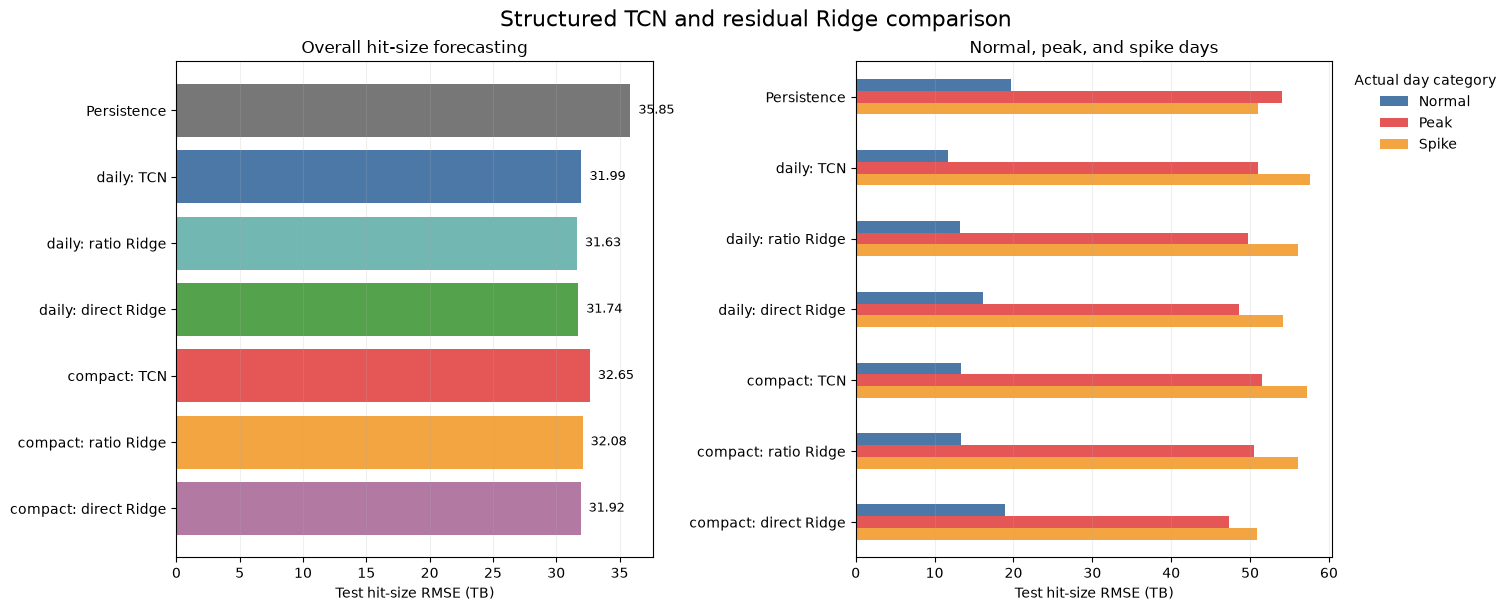

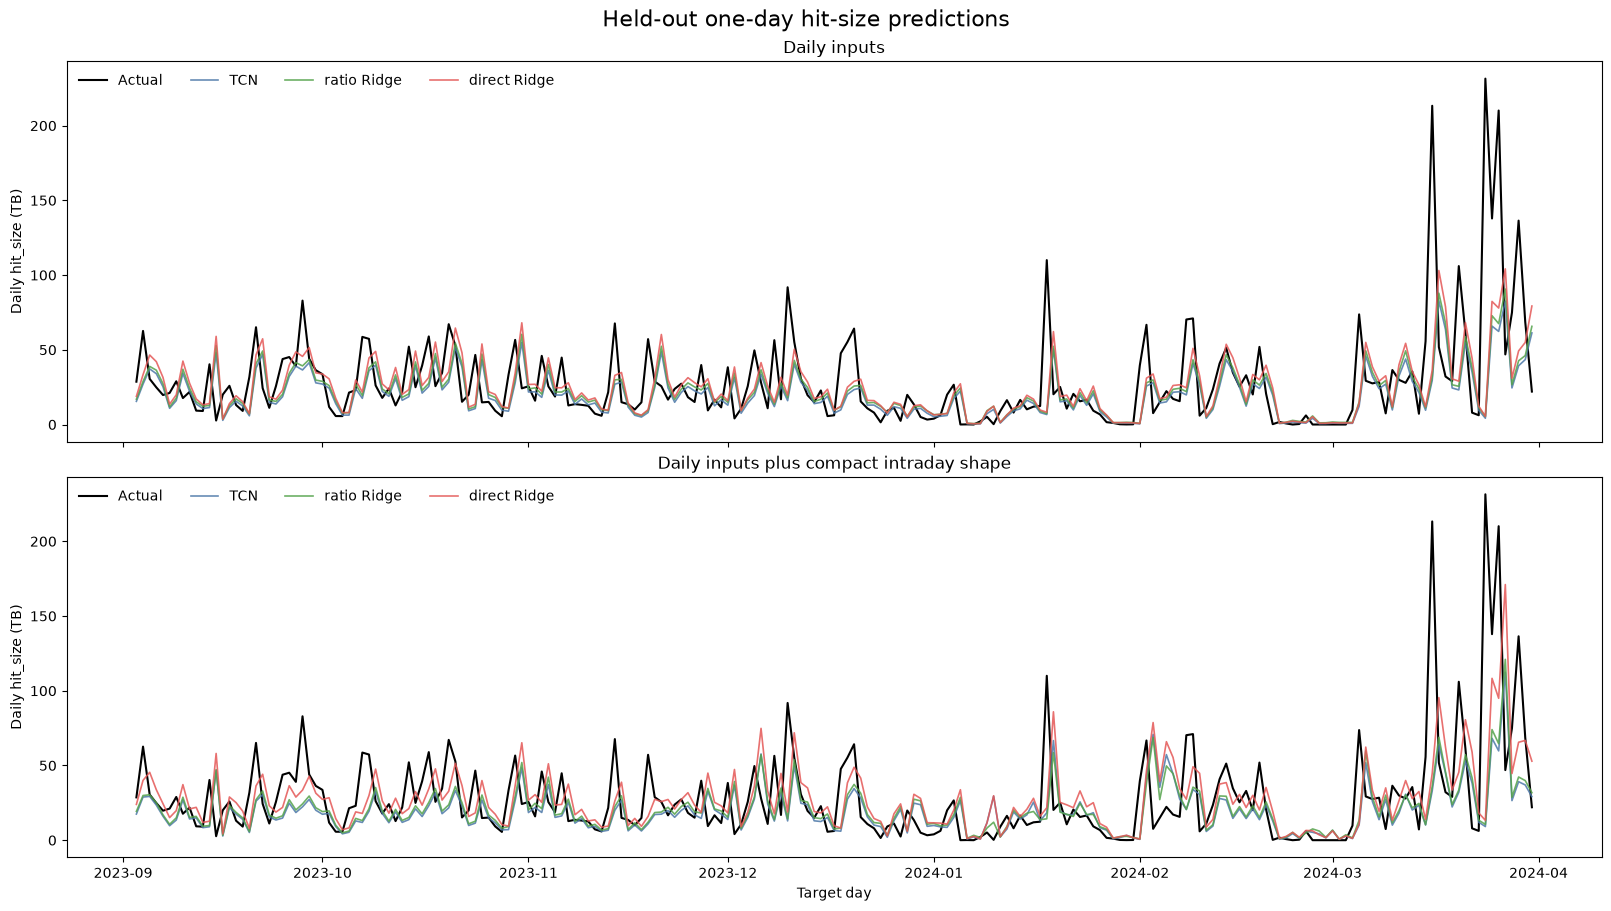

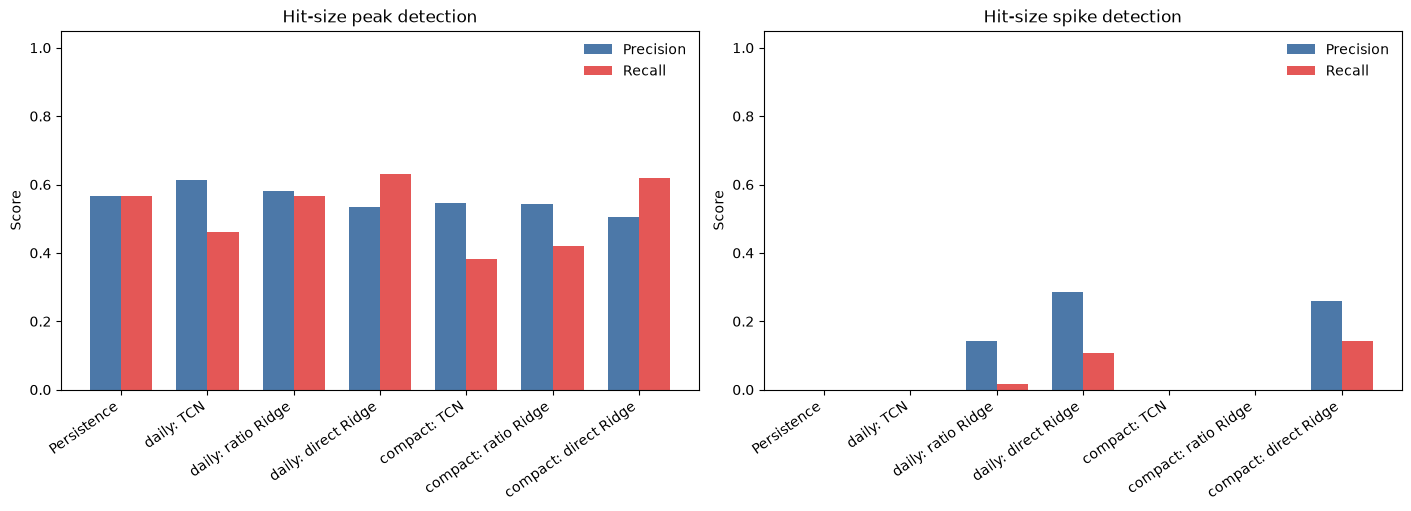

Validation/calibration-selected pipeline: {'family': 'daily_base', 'correction': 'direct', 'criterion': 'TCN validation hit_size RMSE, then calibration CV corrected hit_size RMSE', 'test_used_for_selection': False}
All figures and tables: /Users/dengyingxin/Desktop/xcache/week10/results/whole_range_residual_ridge


In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'week10' / 'Sammy_TCN_261111.ipynb').exists()), None)
if project is None:
    raise FileNotFoundError('Run inside the xcache project.')
figure_dir = project / 'week10' / 'results' / 'whole_range_residual_ridge'
metrics = pd.read_csv(figure_dir / 'all_models_test_metrics.csv')
event_results = pd.read_csv(figure_dir / 'test_hit_size_by_event.csv')
forecasts = pd.read_csv(figure_dir / 'all_models_test_predictions.csv', parse_dates=['target_date'])
locked = json.loads((figure_dir / 'locked_pipeline_selection.json').read_text())
colors = ['#777777', '#4c78a8', '#72b7b2', '#54a24b', '#e45756', '#f2a541', '#b279a2']
display(metrics[['model', 'hit_size_rmse', 'hit_size_improvement_vs_base_pct',
                 'max_size_identity_error', 'peak_precision', 'peak_recall',
                 'spike_precision', 'spike_recall']].round(5))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
labels = metrics.model.str.replace('compact_intraday', 'compact', regex=False).str.replace('daily_base', 'daily', regex=False)
axes[0].barh(labels, metrics.hit_size_rmse, color=colors)
axes[0].invert_yaxis()
axes[0].set(xlabel='Test hit-size RMSE (TB)', title='Overall hit-size forecasting')
for i, value in enumerate(metrics.hit_size_rmse):
    axes[0].text(value, i, f'  {value:.2f}', va='center', fontsize=9)
event_wide = event_results[event_results.category.isin(['Normal', 'Peak', 'Spike'])].pivot(
    index='model', columns='category', values='hit_size_rmse').reindex(metrics.model)
event_wide.index = labels
event_wide[['Normal', 'Peak', 'Spike']].plot.barh(ax=axes[1], color=['#4c78a8', '#e45756', '#f2a541'])
axes[1].invert_yaxis()
axes[1].set(xlabel='Test hit-size RMSE (TB)', ylabel='', title='Normal, peak, and spike days')
axes[1].legend(title='Actual day category', frameon=False,
               loc='upper left', bbox_to_anchor=(1.02, 1.0))
for ax in axes:
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Structured TCN and residual Ridge comparison', fontsize=16)
fig.savefig(figure_dir / 'hit_size_rmse_and_event_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True, constrained_layout=True)
actual = forecasts[forecasts.model == 'daily_base: TCN']
for axis, family, title in zip(axes, ['daily_base', 'compact_intraday'],
                               ['Daily inputs', 'Daily inputs plus compact intraday shape']):
    axis.plot(actual.target_date, actual.hit_size_actual, color='black', linewidth=1.5, label='Actual')
    for method, color in [('TCN', '#4c78a8'), ('ratio Ridge', '#54a24b'), ('direct Ridge', '#e45756')]:
        subset = forecasts[forecasts.model == f'{family}: {method}']
        axis.plot(subset.target_date, subset.hit_size_predicted, label=method, color=color,
                  alpha=.85, linewidth=1.2)
    axis.set(title=title, ylabel='Daily hit_size (TB)')
    axis.legend(loc='upper left', ncol=4, frameon=False)
axes[-1].set_xlabel('Target day')
fig.suptitle('Held-out one-day hit-size predictions', fontsize=16)
fig.savefig(figure_dir / 'test_hit_size_trajectories.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
x = np.arange(len(metrics))
for axis, event in zip(axes, ['peak', 'spike']):
    axis.bar(x - .18, metrics[f'{event}_precision'], .36, label='Precision', color='#4c78a8')
    axis.bar(x + .18, metrics[f'{event}_recall'], .36, label='Recall', color='#e45756')
    axis.set_xticks(x, labels, rotation=35, ha='right')
    axis.set(title=f'Hit-size {event} detection', ylim=(0, 1.05), ylabel='Score')
    axis.legend(frameon=False)
fig.savefig(figure_dir / 'test_peak_spike_precision_recall.png', dpi=180, bbox_inches='tight')
plt.show()
print('Validation/calibration-selected pipeline:', locked)
print('All figures and tables:', figure_dir)

## 9. Access-size residual Ridge and joint access/ratio correction

Extend the frozen models with two physically consistent candidates:

- **Access Ridge:** predict a residual in log1p access-size and retain the TCN size hit ratio.
- **Joint Ridge:** correct both log1p access-size and the size-ratio logit using two Ridge regressors.

Both reconstruct hit-size and miss-size from the corrected access and ratio. All three count outputs remain unchanged. The seven causal Ridge features are identical to the earlier experiment.

Select access and ratio regularization jointly using corrected **hit_size RMSE in TB** on three chronological calibration folds. The joint grid includes disabling either or both corrections. Compare the new candidates with the previously fixed baseline, ratio Ridge, direct Ridge, and persistence. Test results remain descriptive on the reused benchmark.

In [8]:
# This section can be resumed after a kernel restart once frozen forecasts have been saved.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
import joblib
from IPython.display import display

extension_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                       if (p / 'week10' / 'Sammy_TCN_261111.ipynb').exists()), None)
if extension_root is None:
    raise FileNotFoundError('Run this cell inside the xcache project.')
extension_source = extension_root / 'week10' / 'results' / 'whole_range_residual_ridge'
extension_output = extension_source / 'access_joint_extension'
extension_output.mkdir(exist_ok=True)
extension_variables = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
extension_alphas = [1e-4, 1e-3, 1e-2, 0.1, 1., 10., 100., 1000.]
extension_options = [None, *extension_alphas]
extension_epsilon = 1e-4

extension_daily = pd.read_pickle(extension_root / 'xcache-ts-df' / 'socal-2006-2403-daily-ml')
extension_daily = extension_daily.loc['2020-05-31':'2024-03-31', extension_variables].copy()
extension_daily[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
extension_split = pd.read_csv(extension_source / 'chronological_split.csv')
extension_config = json.loads((extension_source / 'experiment_config.json').read_text())
assert extension_config['primary_metric'] == 'hit_size_rmse_tb'
extension_lookback = int(extension_config['lookback'])

def extension_rmse(actual, forecast):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))

def extension_slope(values):
    x = np.arange(len(values), dtype=float)
    x -= x.mean()
    return float(np.dot(x, values) / np.dot(x, x))

extension_causal = pd.DataFrame(index=extension_daily.index)
extension_causal['log_hit_size_lag1'] = np.log1p(extension_daily.hit_size.shift(1))
extension_causal['log_hit_size_lag7'] = np.log1p(extension_daily.hit_size.shift(7))
extension_causal['log_hit_size_ma7'] = np.log1p(extension_daily.hit_size.shift(1).rolling(7).mean())
extension_causal['log_hit_size_ma28'] = np.log1p(extension_daily.hit_size.shift(1).rolling(28).mean())
extension_causal['hit_size_slope7'] = extension_daily.hit_size.shift(1).rolling(7).apply(extension_slope, raw=True)

def extension_read_forecast(family, part):
    path = extension_source / family / f'{part}_frozen_forecasts.csv'
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path.name}. Re-run the cached TCN cells in Sections 3 and 6 once; '
            'matching checkpoints will be loaded without retraining.')
    frame = pd.read_csv(path, parse_dates=['target_date']).set_index('target_date')
    frame = frame[extension_variables]
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert np.isfinite(frame.to_numpy()).all()
    return frame

def extension_make_features(forecast):
    a = forecast.access_size.to_numpy()
    h = forecast.hit_size.to_numpy()
    ratio = np.divide(h, a, out=np.zeros(len(a)), where=a > 0)
    features = pd.DataFrame(index=forecast.index)
    features['predicted_log_access_size'] = np.log1p(a)
    features['predicted_size_ratio_logit'] = logit(np.clip(
        ratio, extension_epsilon, 1 - extension_epsilon))
    for name in extension_causal:
        features[name] = extension_causal.loc[forecast.index, name]
    assert np.isfinite(features.to_numpy()).all()
    return features

extension_families = {}
for family in ['daily_base', 'compact_intraday']:
    calibration = extension_read_forecast(family, 'calibration')
    test = extension_read_forecast(family, 'test')
    assert calibration.index.max() < test.index.min()
    extension_families[family] = dict(
        calibration=calibration, test=test,
        calibration_features=extension_make_features(calibration),
        test_features=extension_make_features(test))
print('Frozen forecast rows per family:',
      {family: (len(data['calibration']), len(data['test']))
       for family, data in extension_families.items()})
print('New TCN training required: no')

Frozen forecast rows per family: {'daily_base': (210, 211), 'compact_intraday': (210, 211)}
New TCN training required: no


### 9.1 Calibration oracle diagnostic

Replace one forecast component with its actual value only to locate the error source. These diagnostic forecasts are not deployable predictions and never enter Ridge features.

Access Ridge models log1p(actual access-size) minus log1p(predicted access-size). Joint Ridge additionally models the actual-minus-predicted clipped ratio logit. Alpha selection always evaluates the final reconstructed hit-size in original TB.

In [12]:
extension_oracle_rows = []
for family, data in extension_families.items():
    forecast = data['calibration']
    actual = extension_daily.loc[forecast.index, extension_variables]
    a, h = actual.access_size.to_numpy(), actual.hit_size.to_numpy()
    ahat, hhat = forecast.access_size.to_numpy(), forecast.hit_size.to_numpy()
    r = np.divide(h, a, out=np.zeros(len(a)), where=a > 0)
    rhat = np.divide(hhat, ahat, out=np.zeros(len(a)), where=ahat > 0)
    for name, hypothetical in [
        ('TCN baseline', hhat),
        ('Oracle actual access + forecast ratio', a * rhat),
        ('Oracle forecast access + actual ratio', ahat * r)]:
        extension_oracle_rows.append(dict(family=family, diagnostic=name,
            calibration_hit_size_rmse_tb=extension_rmse(h, hypothetical)))
extension_oracle = pd.DataFrame(extension_oracle_rows)
extension_oracle.to_csv(extension_output / 'calibration_oracle_diagnostics.csv', index=False)
display(extension_oracle.round(4))

,family,diagnostic,calibration_hit_size_rmse_tb
0,daily_base,TCN baseline,37.5083
1,daily_base,Oracle actual access + forecast ratio,5.8305
2,daily_base,Oracle forecast access + actual ratio,36.2566
3,compact_intraday,TCN baseline,40.0852
4,compact_intraday,Oracle actual access + forecast ratio,7.1246
5,compact_intraday,Oracle forecast access + actual ratio,38.6237


In [9]:
def extension_apply(forecast, access_delta=None, ratio_delta=None):
    if access_delta is None and ratio_delta is None:
        return forecast.copy()
    corrected = forecast.copy()
    a = forecast.access_size.to_numpy()
    h = forecast.hit_size.to_numpy()
    ratio = np.divide(h, a, out=np.zeros(len(a)), where=a > 0)
    if access_delta is not None:
        with np.errstate(over='ignore'):
            a = np.maximum(np.expm1(np.log1p(a) + access_delta), 0)
    if ratio_delta is not None:
        ratio = expit(logit(np.clip(ratio, extension_epsilon, 1 - extension_epsilon))
                      + ratio_delta)
    corrected['access_size'] = a
    corrected['hit_size'] = a * ratio
    corrected['miss_size'] = a * (1 - ratio)
    return corrected

def extension_fit_candidates(family, data, save_dir=None):
    candidate_folder = extension_output if save_dir is None else Path(save_dir)
    candidate_folder.mkdir(parents=True, exist_ok=True)
    forecast = data['calibration']
    actual = extension_daily.loc[forecast.index, extension_variables]
    features = data['calibration_features']
    ratio_actual = np.divide(actual.hit_size, actual.access_size,
                             out=np.zeros(len(actual)), where=actual.access_size > 0)
    ratio_forecast = np.divide(forecast.hit_size, forecast.access_size,
                               out=np.zeros(len(forecast)), where=forecast.access_size > 0)
    targets = dict(
        access=np.log1p(actual.access_size.to_numpy()) - np.log1p(forecast.access_size.to_numpy()),
        ratio=logit(np.clip(np.asarray(ratio_actual), extension_epsilon, 1 - extension_epsilon))
              - logit(np.clip(np.asarray(ratio_forecast), extension_epsilon, 1 - extension_epsilon)))
    folds = []
    for fold, (train_index, valid_index) in enumerate(TimeSeriesSplit(n_splits=3).split(features), 1):
        assert features.index[train_index].max() < features.index[valid_index].min()
        cache = dict(access={None: None}, ratio={None: None})
        for component in ['access', 'ratio']:
            fit_index = train_index
            if component == 'ratio':
                fit_index = train_index[actual.access_size.iloc[train_index].to_numpy() > 0]
            if len(fit_index) < 5:
                raise ValueError('Too few calibration rows to fit a residual correction.')
            for alpha in extension_alphas:
                pipeline = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
                pipeline.fit(features.iloc[fit_index], targets[component][fit_index])
                cache[component][alpha] = pipeline.predict(features.iloc[valid_index])
        folds.append(dict(fold=fold, train_index=train_index, valid_index=valid_index, cache=cache))

    candidate_rows, fold_rows = [], []
    for method in ['access', 'joint']:
        options = ([(alpha, None) for alpha in extension_options] if method == 'access'
                   else [(aa, ar) for aa in extension_options for ar in extension_options])
        for alpha_access, alpha_ratio in options:
            squared_errors = []
            for fold in folds:
                ti, vi, cache = fold['train_index'], fold['valid_index'], fold['cache']
                corrected = extension_apply(forecast.iloc[vi],
                    cache['access'][alpha_access], cache['ratio'][alpha_ratio])
                delta = corrected.hit_size.to_numpy() - actual.hit_size.iloc[vi].to_numpy()
                finite = np.isfinite(delta).all()
                fold_score = float(np.sqrt(np.mean(delta ** 2))) if finite else np.inf
                squared_errors.extend(delta ** 2 if finite else np.full(len(vi), np.inf))
                fold_rows.append(dict(family=family, method=method,
                    alpha_access=alpha_access, alpha_ratio=alpha_ratio, fold=fold['fold'],
                    train_end=features.index[ti[-1]], validation_start=features.index[vi[0]],
                    validation_end=features.index[vi[-1]], validation_days=len(vi),
                    corrected_hit_size_rmse_tb=fold_score))
            candidate_rows.append(dict(
                family=family, method=method, alpha_access=alpha_access, alpha_ratio=alpha_ratio,
                access_enabled=alpha_access is not None, ratio_enabled=alpha_ratio is not None,
                calibration_cv_hit_size_rmse=float(np.sqrt(np.mean(squared_errors)))))
    candidates = pd.DataFrame(candidate_rows)
    winners = {}
    for method in ['access', 'joint']:
        options = [r for r in candidate_rows if r['method'] == method]
        winner = min(options, key=lambda r: (
            r['calibration_cv_hit_size_rmse'], int(r['access_enabled']) + int(r['ratio_enabled'])))
        fitted = {}
        for component, alpha in [('access', winner['alpha_access']), ('ratio', winner['alpha_ratio'])]:
            if alpha is None:
                continue
            mask = actual.access_size.to_numpy() > 0 if component == 'ratio' else np.ones(len(actual), dtype=bool)
            pipeline = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
            pipeline.fit(features.loc[mask], targets[component][mask])
            fitted[component] = pipeline
            pd.DataFrame(dict(feature=features.columns,
                              standardized_coefficient=pipeline.named_steps['ridge'].coef_)).to_csv(
                candidate_folder / f'{family}_{method}_{component}_coefficients.csv', index=False)
        winners[method] = dict(**winner, pipelines=fitted)
        joblib.dump(fitted, candidate_folder / f'{family}_{method}_ridge_pipelines.joblib')
    candidates.to_csv(candidate_folder / f'{family}_alpha_scan.csv', index=False)
    pd.DataFrame(fold_rows).to_csv(candidate_folder / f'{family}_chronological_cv_folds.csv', index=False)
    (candidate_folder / f'{family}_selected_ridge.json').write_text(json.dumps([
        {k: v for k, v in choice.items() if k != 'pipelines'}
        for choice in winners.values()], indent=2), encoding='utf-8')
    return winners

extension_selected = {}
for family, data in extension_families.items():
    extension_selected[family] = extension_fit_candidates(family, data)

extension_selection_table = pd.DataFrame([
    {k: v for k, v in choice.items() if k != 'pipelines'}
    for winners in extension_selected.values() for choice in winners.values()
])
extension_selection_table.to_csv(extension_output / 'new_ridge_selection_summary.csv', index=False)
display(extension_selection_table.round(5))

# Lock the expanded pipeline using the original validation-selected input family.
original_family_table = pd.read_csv(extension_source / 'tcn_validation_comparison.csv')
extension_locked_family = str(original_family_table.sort_values('validation_hit_size_rmse').iloc[0].family)
original_scan = pd.read_csv(extension_source / extension_locked_family / 'ridge_alpha_scan.csv')
selection_options = [{
    'family': extension_locked_family, 'method': 'TCN', 'correction_enabled': False,
    'calibration_cv_hit_size_rmse': float(original_scan.loc[~original_scan.correction_enabled]
                                       .iloc[0].calibration_cv_hit_size_rmse)}]
for method in ['ratio', 'direct']:
    choice = original_scan[original_scan.method == method].sort_values('calibration_cv_hit_size_rmse').iloc[0]
    if bool(choice.correction_enabled):
        selection_options.append(dict(family=extension_locked_family, method=f'{method} Ridge',
            correction_enabled=True, calibration_cv_hit_size_rmse=float(choice.calibration_cv_hit_size_rmse)))
for method, choice in extension_selected[extension_locked_family].items():
    if choice['access_enabled'] or choice['ratio_enabled']:
        selection_options.append(dict(family=extension_locked_family, method=f'{method} Ridge',
            correction_enabled=True, calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse']))
extension_locked = min(selection_options, key=lambda r: r['calibration_cv_hit_size_rmse'])
extension_locked['model'] = f"{extension_locked['family']}: {extension_locked['method']}"
extension_locked['test_used_for_selection'] = False
(extension_output / 'locked_expanded_pipeline.json').write_text(
    json.dumps(extension_locked, indent=2), encoding='utf-8')
print('Expanded selection locked before new test scoring:', extension_locked)

,family,method,alpha_access,alpha_ratio,access_enabled,ratio_enabled,calibration_cv_hit_size_rmse
0,daily_base,access,100.0000,NaN,True,False,40.79541
1,daily_base,joint,100.0000,100.0000,True,True,39.78981
2,compact_intraday,access,0.0001,NaN,True,False,39.67394
3,compact_intraday,joint,100.0000,0.0001,True,True,39.19659


Expanded selection locked before new test scoring: {'family': 'daily_base', 'method': 'direct Ridge', 'correction_enabled': True, 'calibration_cv_hit_size_rmse': 39.68691436513946, 'model': 'daily_base: direct Ridge', 'test_used_for_selection': False}


### 9.2 Test comparison of every correction

The expanded comparison contains persistence and five methods per TCN input family: TCN alone, ratio Ridge, direct Ridge, access Ridge, and joint Ridge. A disabled correction can duplicate the TCN or a one-component correction.

Report all six RMSEs and size identity error. Access/joint correction can improve hit-size while worsening miss-size or access-size; the full table makes that tradeoff visible. New results are saved in `access_joint_extension`, preserving the earlier comparison.

In [14]:
extension_original_predictions = pd.read_csv(extension_source / 'all_models_test_predictions.csv',
                                             parse_dates=['target_date'])
extension_prediction_frames = [extension_original_predictions]
extension_original_metrics = pd.read_csv(extension_source / 'all_models_test_metrics.csv')
extension_model_meta = {row['model']: dict(
    family=row['family'], correction=row['correction'], enabled=bool(row['enabled']),
    calibration_cv_hit_size_rmse=float(row['calibration_cv_hit_size_rmse']))
    for row in extension_original_metrics.to_dict('records')}

for family, data in extension_families.items():
    features = data['test_features']
    for method, choice in extension_selected[family].items():
        corrections = {component: pipeline.predict(features)
                       for component, pipeline in choice['pipelines'].items()}
        forecast = extension_apply(data['test'], corrections.get('access'), corrections.get('ratio'))
        assert np.isfinite(forecast.to_numpy()).all()
        assert (forecast.to_numpy() >= 0).all()
        label = f'{family}: {method} Ridge'
        actual = extension_daily.loc[forecast.index, extension_variables]
        frame = pd.DataFrame({'model': label, 'target_date': forecast.index})
        for variable in extension_variables:
            frame[f'{variable}_actual'] = actual[variable].to_numpy()
            frame[f'{variable}_predicted'] = forecast[variable].to_numpy()
        extension_prediction_frames.append(frame)
        extension_model_meta[label] = dict(family=family, correction=method,
            enabled=bool(choice['pipelines']),
            calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse'])

extension_predictions = pd.concat(extension_prediction_frames, ignore_index=True)
train_info = extension_split[extension_split.subset == 'train'].iloc[0]
extension_training_hit = extension_daily.loc[train_info.first_day:train_info.last_day, 'hit_size']
extension_peak_threshold = float(extension_training_hit.quantile(.90))
extension_spike_threshold = float(extension_training_hit.diff().dropna().quantile(.90))
extension_metric_rows, extension_event_rows = [], []
for label, group in extension_predictions.groupby('model', sort=False):
    group = group.sort_values('target_date')
    positions = extension_daily.index.get_indexer(group.target_date)
    assert (positions > 0).all()
    actual = group.hit_size_actual.to_numpy()
    predicted = group.hit_size_predicted.to_numpy()
    previous = extension_daily.hit_size.iloc[positions - 1].to_numpy()
    residual = predicted - actual
    identity = group.access_size_predicted - group.hit_size_predicted - group.miss_size_predicted
    peak = actual >= extension_peak_threshold
    spike = (actual - previous) >= extension_spike_threshold
    categories = dict(Overall=np.ones(len(group), dtype=bool), Normal=~(peak | spike), Peak=peak, Spike=spike)
    row = dict(model=label, **extension_model_meta[label], is_locked_selection=label == extension_locked['model'],
        hit_size_mae=float(np.abs(residual).mean()), hit_size_bias=float(residual.mean()),
        max_size_identity_error=float(np.abs(identity).max()),
        mean_size_identity_error=float(np.abs(identity).mean()), test_days=len(group))
    for variable in extension_variables:
        row[f'{variable}_rmse'] = extension_rmse(group[f'{variable}_actual'], group[f'{variable}_predicted'])
    for event, observed in [('peak', peak), ('spike', spike)]:
        forecast_event = predicted >= extension_peak_threshold if event == 'peak' else predicted - previous >= extension_spike_threshold
        tp = int(np.sum(observed & forecast_event))
        row[f'{event}_days'] = int(observed.sum())
        row[f'predicted_{event}_days'] = int(forecast_event.sum())
        row[f'{event}_precision'] = tp / int(forecast_event.sum()) if forecast_event.any() else 0.
        row[f'{event}_recall'] = tp / int(observed.sum()) if observed.any() else np.nan
    for category, mask in categories.items():
        extension_event_rows.append(dict(model=label, category=category, days=int(mask.sum()),
            hit_size_rmse=extension_rmse(actual[mask], predicted[mask]) if mask.any() else np.nan,
            bias=float(residual[mask].mean()) if mask.any() else np.nan))
    extension_metric_rows.append(row)

extension_metrics = pd.DataFrame(extension_metric_rows)
extension_base_score = float(extension_metrics.loc[extension_metrics.model == 'daily_base: TCN', 'hit_size_rmse'].iloc[0])
extension_metrics['hit_size_improvement_vs_base_pct'] = (
    100 * (extension_base_score - extension_metrics.hit_size_rmse) / extension_base_score)
extension_metrics.to_csv(extension_output / 'expanded_all_models_test_metrics.csv', index=False)
extension_predictions.to_csv(extension_output / 'expanded_all_models_test_predictions.csv', index=False)
pd.DataFrame(extension_event_rows).to_csv(extension_output / 'expanded_hit_size_by_event.csv', index=False)
extension_six_rmse = extension_metrics.set_index('model')[[f'{v}_rmse' for v in extension_variables]]
extension_six_rmse.columns = extension_variables
extension_six_rmse.to_csv(extension_output / 'expanded_six_variable_test_rmse.csv')
display(extension_metrics[['model', 'is_locked_selection', 'hit_size_rmse',
    'hit_size_improvement_vs_base_pct', 'access_size_rmse', 'miss_size_rmse',
    'max_size_identity_error', 'peak_recall', 'spike_recall']].round(5))
display(extension_six_rmse.round(4))
print('Validation/calibration-selected expanded pipeline:', extension_locked['model'])

,model,is_locked_selection,hit_size_rmse,hit_size_improvement_vs_base_pct,access_size_rmse,miss_size_rmse,max_size_identity_error,peak_recall,spike_recall
0,Persistence,False,35.85180,-12.06394,36.41841,0.85243,0.00000,0.56579,0.00000
1,daily_base: TCN,False,31.99227,0.00000,32.05592,2.63845,0.00000,0.46053,0.00000
2,daily_base: ratio Ridge,False,31.63074,1.13007,32.05592,0.78855,0.00000,0.56579,0.01786
3,daily_base: direct Ridge,True,31.73654,0.79936,32.05592,2.63845,21.58583,0.63158,0.10714
4,compact_intraday: TCN,False,32.65016,-2.05640,33.07485,3.68030,0.00000,0.38158,0.00000
5,compact_intraday: ratio Ridge,False,32.08000,-0.27420,33.07485,3.81300,0.00000,0.42105,0.00000
6,compact_intraday: direct Ridge,False,31.92428,0.21254,33.07485,3.68030,58.69565,0.61842,0.14286
7,daily_base: access Ridge,False,31.75776,0.73302,32.12558,3.01508,0.00000,0.60526,0.03571
8,daily_base: joint Ridge,False,31.66426,1.02528,32.12558,0.83350,0.00000,0.61842,0.10714
9,compact_intraday: access Ridge,False,30.83366,3.62154,31.38590,3.70031,0.00000,0.61842,0.00000


,access_count,access_size,hit_count,hit_size,miss_count,miss_size
model,,,,,,
Persistence,14526.6927,36.4184,13668.5245,35.8518,1162.6244,0.8524
daily_base: TCN,17902.6391,32.0559,15033.7212,31.9923,4265.3814,2.6385
daily_base: ratio Ridge,17902.6391,32.0559,15033.7212,31.6307,4265.3814,0.7885
daily_base: direct Ridge,17902.6391,32.0559,15033.7212,31.7365,4265.3814,2.6385
compact_intraday: TCN,17130.9760,33.0749,15104.3472,32.6502,3414.0576,3.6803
compact_intraday: ratio Ridge,17130.9760,33.0749,15104.3472,32.0800,3414.0576,3.8130
compact_intraday: direct Ridge,17130.9760,33.0749,15104.3472,31.9243,3414.0576,3.6803
daily_base: access Ridge,17902.6391,32.1256,15033.7212,31.7578,4265.3814,3.0151
daily_base: joint Ridge,17902.6391,32.1256,15033.7212,31.6643,4265.3814,0.8335


Validation/calibration-selected expanded pipeline: daily_base: direct Ridge


### 9.3 Reloadable expanded visualizations

This cell reads the expanded CSVs independently after a kernel restart. The baseline and earlier Ridge methods stay in the comparison. Improvement percentages refer to the same daily TCN and identical test dates.

,model,is_locked_selection,hit_size_rmse,access_size_rmse,miss_size_rmse,hit_size_improvement_vs_base_pct,max_size_identity_error,peak_recall,spike_recall
0,Persistence,False,35.85180,36.41841,0.85243,-12.06394,0.00000,0.56579,0.00000
1,daily_base: TCN,False,31.99227,32.05592,2.63845,0.00000,0.00000,0.46053,0.00000
2,daily_base: ratio Ridge,False,31.63074,32.05592,0.78855,1.13007,0.00000,0.56579,0.01786
3,daily_base: direct Ridge,True,31.73654,32.05592,2.63845,0.79936,21.58583,0.63158,0.10714
4,compact_intraday: TCN,False,32.65016,33.07485,3.68030,-2.05640,0.00000,0.38158,0.00000
5,compact_intraday: ratio Ridge,False,32.08000,33.07485,3.81300,-0.27420,0.00000,0.42105,0.00000
6,compact_intraday: direct Ridge,False,31.92428,33.07485,3.68030,0.21254,58.69565,0.61842,0.14286
7,daily_base: access Ridge,False,31.75776,32.12558,3.01508,0.73302,0.00000,0.60526,0.03571
8,daily_base: joint Ridge,False,31.66426,32.12558,0.83350,1.02528,0.00000,0.61842,0.10714
9,compact_intraday: access Ridge,False,30.83366,31.38590,3.70031,3.62154,0.00000,0.61842,0.00000


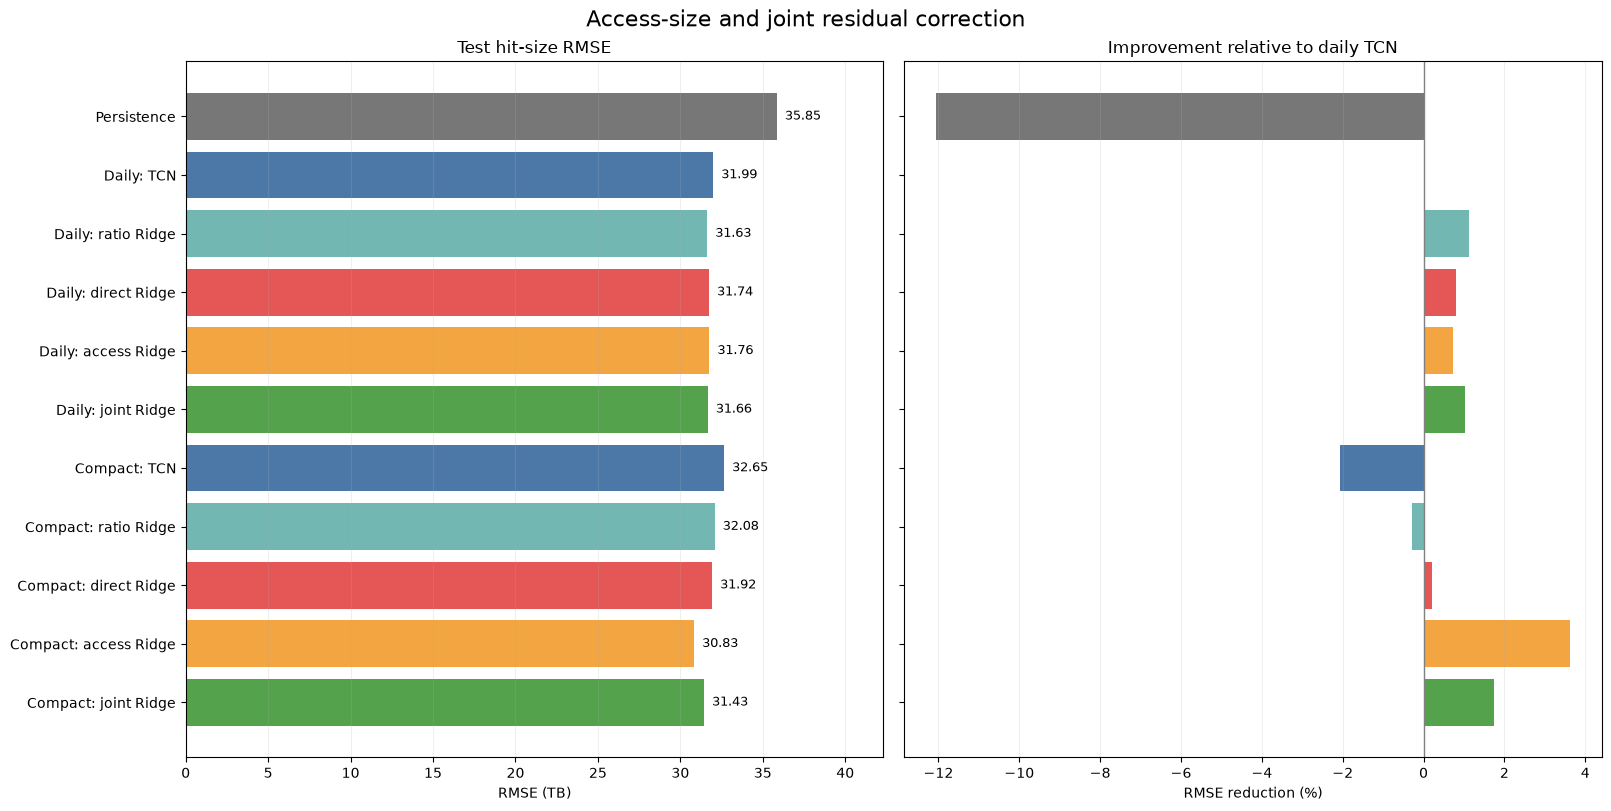

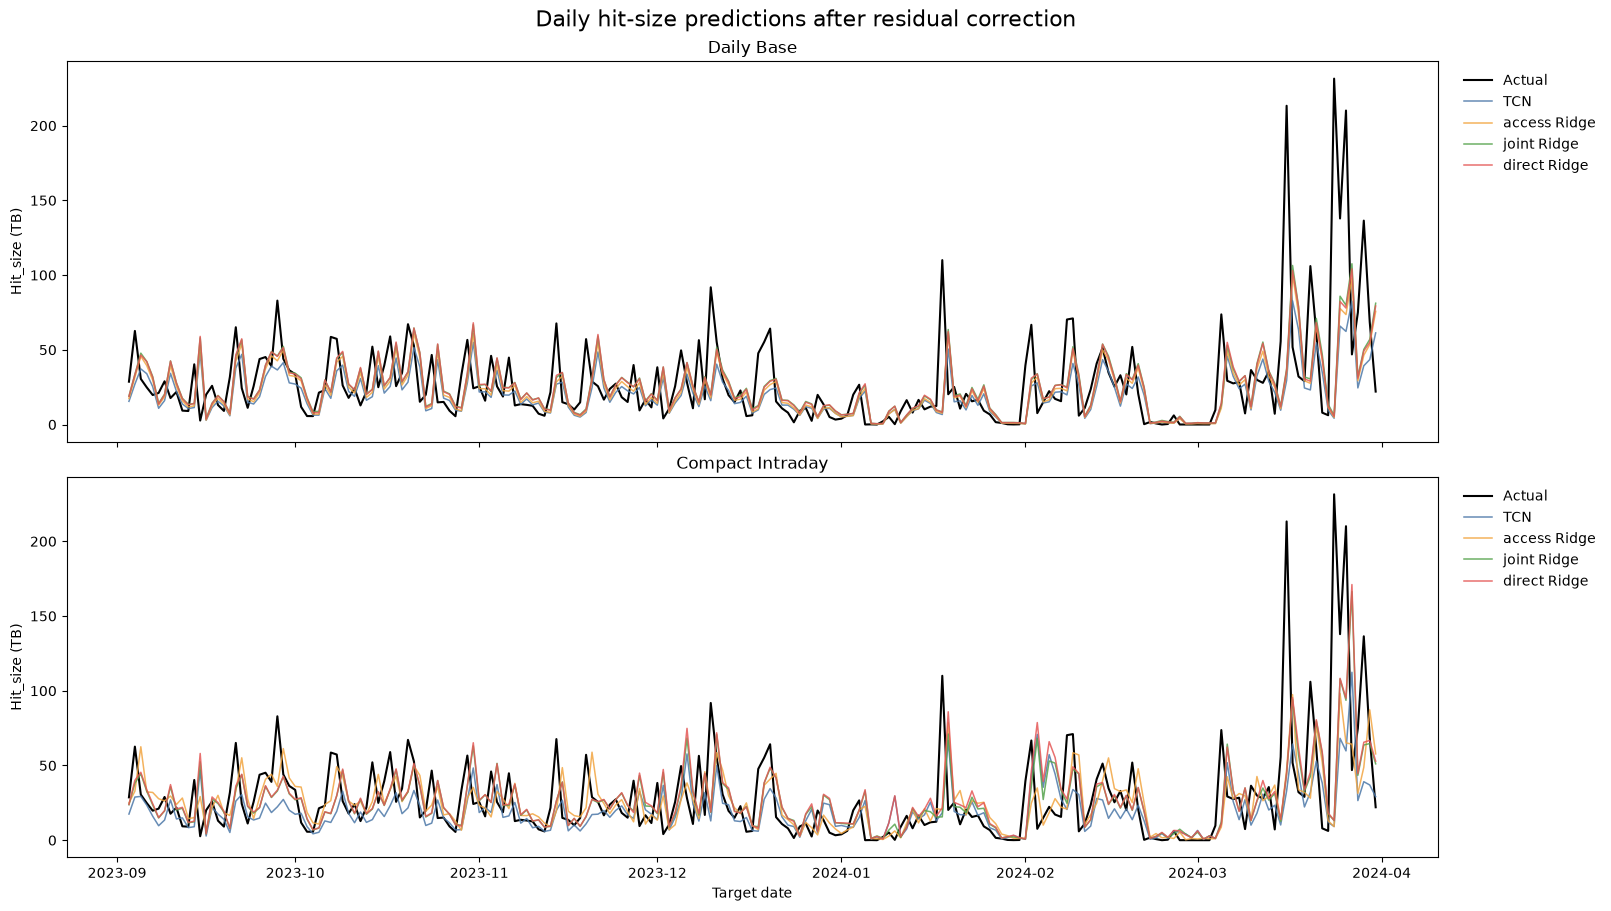

Selected before test scoring: daily_base: direct Ridge
Expanded results saved to: /Users/dengyingxin/Desktop/xcache/week10/results/whole_range_residual_ridge/access_joint_extension


In [15]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_project = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'week10' / 'Sammy_TCN_261111.ipynb').exists()), None)
if plot_project is None:
    raise FileNotFoundError('Run inside the xcache project.')
expanded_dir = plot_project / 'week10' / 'results' / 'whole_range_residual_ridge' / 'access_joint_extension'
expanded_metrics = pd.read_csv(expanded_dir / 'expanded_all_models_test_metrics.csv')
expanded_forecasts = pd.read_csv(expanded_dir / 'expanded_all_models_test_predictions.csv', parse_dates=['target_date'])
expanded_locked = json.loads((expanded_dir / 'locked_expanded_pipeline.json').read_text())
display(expanded_metrics[['model', 'is_locked_selection', 'hit_size_rmse',
    'access_size_rmse', 'miss_size_rmse', 'hit_size_improvement_vs_base_pct',
    'max_size_identity_error', 'peak_recall', 'spike_recall']].round(5))

plot_order = ['Persistence'] + [f'{family}: {method}' for family in ['daily_base', 'compact_intraday']
                               for method in ['TCN', 'ratio Ridge', 'direct Ridge', 'access Ridge', 'joint Ridge']]
ordered = expanded_metrics.set_index('model').reindex(plot_order)
short_labels = [label.replace('daily_base:', 'Daily:').replace('compact_intraday:', 'Compact:')
                for label in plot_order]
method_colors = {'TCN': '#4c78a8', 'ratio Ridge': '#72b7b2', 'direct Ridge': '#e45756',
                 'access Ridge': '#f2a541', 'joint Ridge': '#54a24b'}
bar_colors = ['#777777'] + [method_colors[label.split(': ')[1]] for label in plot_order[1:]]
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True, constrained_layout=True)
y = np.arange(len(ordered))
axes[0].barh(y, ordered.hit_size_rmse, color=bar_colors)
axes[0].set_yticks(y, short_labels)
axes[0].invert_yaxis()
axes[0].set(title='Test hit-size RMSE', xlabel='RMSE (TB)')
axes[0].set_xlim(0, float(ordered.hit_size_rmse.max()) * 1.18)
for i, value in enumerate(ordered.hit_size_rmse):
    axes[0].text(value, i, f'  {value:.2f}', va='center', fontsize=9)
axes[1].barh(y, ordered.hit_size_improvement_vs_base_pct, color=bar_colors)
axes[1].axvline(0, color='gray', linewidth=1)
axes[1].set(title='Improvement relative to daily TCN', xlabel='RMSE reduction (%)')
for axis in axes:
    axis.grid(axis='x', alpha=.2)
fig.suptitle('Access-size and joint residual correction', fontsize=16)
fig.savefig(expanded_dir / 'expanded_hit_size_rmse_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True, constrained_layout=True)
for axis, family in zip(axes, ['daily_base', 'compact_intraday']):
    observed = expanded_forecasts[expanded_forecasts.model == f'{family}: TCN']
    axis.plot(observed.target_date, observed.hit_size_actual, color='black', linewidth=1.5, label='Actual')
    for method in ['TCN', 'access Ridge', 'joint Ridge', 'direct Ridge']:
        subset = expanded_forecasts[expanded_forecasts.model == f'{family}: {method}']
        axis.plot(subset.target_date, subset.hit_size_predicted,
                  color=method_colors[method], label=method, linewidth=1.1, alpha=.85)
    axis.set(title=family.replace('_', ' ').title(), ylabel='Hit_size (TB)')
    axis.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1.0))
axes[-1].set_xlabel('Target date')
fig.suptitle('Daily hit-size predictions after residual correction', fontsize=16)
fig.savefig(expanded_dir / 'expanded_hit_size_trajectories.png', dpi=180, bbox_inches='tight')
plt.show()
print('Selected before test scoring:', expanded_locked['model'])
print('Expanded results saved to:', expanded_dir)

## 10. Five-seed robustness of the three lowest test hit-size RMSE candidates

Freeze the shortlist from the existing seed-42 test ranking: compact intraday + Access Ridge, compact intraday + Joint Ridge, and daily base + Ratio Ridge.

Run seeds **42, 7, 21, 84, 2026** on the same chronological split. The two compact candidates share the same underlying TCN at each seed. Each seed selects its TCN checkpoint by validation hit-size RMSE and Ridge alpha by chronological calibration CV. Keep the candidate identities fixed across seeds.

Report all six variables' RMSE, peak/spike precision and recall, and median/IQR across seeds. Include the corresponding uncorrected TCNs and deterministic persistence. This evaluates random-initialization sensitivity on a fixed, reused test period. The initial shortlist used test performance, so these are exploratory robustness results rather than an independent final evaluation.

In [10]:
ROBUSTNESS_SEEDS = [42, 7, 21, 84, 2026]
ROBUSTNESS_DIR = OUTPUT_DIR / 'top3_seed_robustness'
ROBUSTNESS_DIR.mkdir(exist_ok=True)
manifest_path = ROBUSTNESS_DIR / 'frozen_shortlist.json'
if manifest_path.exists():
    robustness_manifest = json.loads(manifest_path.read_text())
    if robustness_manifest['seeds'] != ROBUSTNESS_SEEDS:
        raise ValueError('The saved robustness seed list differs from this configuration.')
else:
    source_rank = pd.read_csv(extension_output / 'expanded_all_models_test_metrics.csv')
    source_rank = source_rank[source_rank.model != 'Persistence'].sort_values('hit_size_rmse').head(3)
    robustness_manifest = dict(
        selected_by='seed-42 reused-test hit_size RMSE',
        exploratory=True, seeds=ROBUSTNESS_SEEDS,
        candidates=[dict(model=str(row.model), seed42_test_hit_size_rmse=float(row.hit_size_rmse))
                    for row in source_rank.itertuples()])
    save_json(manifest_path, robustness_manifest)
ROBUSTNESS_MODELS = [row['model'] for row in robustness_manifest['candidates']]
expected_models = {'compact_intraday: access Ridge', 'compact_intraday: joint Ridge', 'daily_base: ratio Ridge'}
if set(ROBUSTNESS_MODELS) != expected_models:
    raise ValueError('The saved shortlist differs from the three agreed candidates.')
robustness_training_positions = SPLITS['train']
robustness_thresholds = pd.DataFrame([
    dict(variable=name,
         peak_threshold=float(np.quantile(RAW[robustness_training_positions, i], .90)),
         spike_threshold=float(np.quantile(np.diff(RAW[robustness_training_positions, i]), .90)),
         unit='requests' if 'count' in name else 'TB')
    for i, name in enumerate(FEATURE_NAMES)
])
robustness_thresholds.to_csv(ROBUSTNESS_DIR / 'training_event_thresholds.csv', index=False)
display(pd.DataFrame(robustness_manifest['candidates']))
print('Fixed candidate identities:', ROBUSTNESS_MODELS)
print('Five paired seeds:', ROBUSTNESS_SEEDS)
print('This is initialization robustness on one fixed split, not rolling-window robustness.')

,model,seed42_test_hit_size_rmse
0,compact_intraday: access Ridge,30.833661
1,compact_intraday: joint Ridge,31.434307
2,daily_base: ratio Ridge,31.630739


Fixed candidate identities: ['compact_intraday: access Ridge', 'compact_intraday: joint Ridge', 'daily_base: ratio Ridge']
Five paired seeds: [42, 7, 21, 84, 2026]
This is initialization robustness on one fixed split, not rolling-window robustness.


### 10.1 Shared scoring and per-seed execution

Every target is a one-day-ahead prediction. Spike detection compares the next-day forecast with the last observed actual value, not with yesterday's forecast. Thresholds use the original 840-day training period and remain identical across models and seeds.

For all six variables, a peak is a positive level at least the training 90th percentile. A spike is a positive one-day increase at least the training 90th percentile of changes. Positivity avoids classifying zero-traffic days as events when a threshold is zero. Peak/spike groups can overlap.

Precision is reported with recall to expose false alarms. No-event recall is NaN; precision is zero when no event is predicted. Persist seed-level checkpoints, predictions, calibration selections, and metrics so interrupted runs can resume.

In [11]:
def robustness_score(model_name, seed, forecast, metadata=None):
    positions = TARGETS['test']
    observed = RAW[positions]
    previous = RAW[positions - 1]
    forecast = np.asarray(forecast, dtype=float)
    assert forecast.shape == observed.shape and np.isfinite(forecast).all()
    assert (forecast >= 0).all()
    row = dict(model=model_name, seed=int(seed), test_days=len(positions),
               max_size_identity_error=float(np.abs(forecast[:, 1] - forecast[:, 3] - forecast[:, 5]).max()),
               max_count_identity_error=float(np.abs(forecast[:, 0] - forecast[:, 2] - forecast[:, 4]).max()))
    row.update(metadata or {})
    event_rows, prediction_rows = [], []
    for i, variable in enumerate(FEATURE_NAMES):
        row[f'{variable}_rmse'] = rmse(observed[:, i], forecast[:, i])
        threshold = robustness_thresholds[robustness_thresholds.variable == variable].iloc[0]
        actual_change = observed[:, i] - previous[:, i]
        predicted_change = forecast[:, i] - previous[:, i]
        actual_peak = (observed[:, i] > 0) & (observed[:, i] >= threshold.peak_threshold)
        predicted_peak = (forecast[:, i] > 0) & (forecast[:, i] >= threshold.peak_threshold)
        actual_spike = (actual_change > 0) & (actual_change >= threshold.spike_threshold)
        predicted_spike = (predicted_change > 0) & (predicted_change >= threshold.spike_threshold)
        for event, actual_mask, predicted_mask, limit in [
            ('peak', actual_peak, predicted_peak, threshold.peak_threshold),
            ('spike', actual_spike, predicted_spike, threshold.spike_threshold)]:
            tp = int((actual_mask & predicted_mask).sum())
            fp = int((~actual_mask & predicted_mask).sum())
            fn = int((actual_mask & ~predicted_mask).sum())
            actual_days, predicted_days = int(actual_mask.sum()), int(predicted_mask.sum())
            precision = tp / predicted_days if predicted_days else 0.
            recall = tp / actual_days if actual_days else np.nan
            error = forecast[actual_mask, i] - observed[actual_mask, i]
            event_rows.append(dict(model=model_name, seed=int(seed), variable=variable,
                event=event, threshold=float(limit), actual_event_days=actual_days,
                predicted_event_days=predicted_days, true_positive=tp, false_positive=fp,
                false_negative=fn, precision=precision, recall=recall,
                event_rmse=rmse(observed[actual_mask, i], forecast[actual_mask, i]) if actual_days else np.nan,
                event_bias=float(error.mean()) if actual_days else np.nan))
            if variable == 'hit_size':
                row[f'{event}_recall'] = recall
                row[f'{event}_precision'] = precision
                row[f'{event}_days'] = actual_days
    for j, date in enumerate(daily.index[positions]):
        record = dict(model=model_name, seed=int(seed), target_date=date)
        for i, variable in enumerate(FEATURE_NAMES):
            record[f'{variable}_actual'] = observed[j, i]
            record[f'{variable}_predicted'] = forecast[j, i]
        prediction_rows.append(record)
    return row, event_rows, prediction_rows

def run_robustness_seed(seed):
    seed = int(seed)
    seed_dir = ROBUSTNESS_DIR / f'seed_{seed}'
    seed_dir.mkdir(exist_ok=True)
    metric_rows, all_events, all_predictions = [], [], []
    original_test = pd.read_csv(extension_output / 'expanded_all_models_test_metrics.csv').set_index('model')
    for family, use_shapes in [('compact_intraday', True), ('daily_base', False)]:
        print(f'ROBUSTNESS seed={seed}, family={family}', flush=True)
        # Reuse the original seed-42 checkpoints; new seeds have separate cache folders.
        model_dir = OUTPUT_DIR if seed == 42 else seed_dir
        bundle = train_family(family, use_shapes, seed=seed, run_output_dir=model_dir)
        baseline_forecast = bundle['forecasts']['test']
        baseline_label = f'{family}: TCN'
        baseline_metadata = dict(is_candidate=False, family=family, method='none',
            best_epoch=bundle['metadata']['best_epoch'],
            validation_hit_size_rmse=bundle['metadata']['validation_hit_size_rmse'],
            correction_enabled=False, calibration_cv_hit_size_rmse=np.nan)
        baseline_row, baseline_events, baseline_predictions = robustness_score(
            baseline_label, seed, baseline_forecast, baseline_metadata)
        metric_rows.append(baseline_row)
        all_events.extend(baseline_events)
        all_predictions.extend(baseline_predictions)
        fitted_choices = {}
        if family == 'compact_intraday':
            cal_frame = pd.DataFrame(bundle['forecasts']['calibration'],
                                     index=daily.index[TARGETS['calibration']], columns=FEATURE_NAMES)
            test_frame = pd.DataFrame(baseline_forecast,
                                      index=daily.index[TARGETS['test']], columns=FEATURE_NAMES)
            correction_data = dict(calibration=cal_frame, test=test_frame,
                calibration_features=extension_make_features(cal_frame),
                test_features=extension_make_features(test_frame))
            choices = extension_fit_candidates(family, correction_data,
                                               save_dir=seed_dir / 'ridge')
            for method in ['access', 'joint']:
                choice = choices[method]
                delta = {component: pipeline.predict(correction_data['test_features'])
                         for component, pipeline in choice['pipelines'].items()}
                corrected = extension_apply(test_frame, delta.get('access'), delta.get('ratio')).to_numpy()
                fitted_choices[method] = dict(prediction=corrected,
                    enabled=bool(choice['pipelines']), alpha_access=choice['alpha_access'],
                    alpha_ratio=choice['alpha_ratio'],
                    calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse'])
        else:
            bundle = tune_corrections(bundle, run_output_dir=seed_dir / 'ridge')
            choice = bundle['corrections']['ratio']
            corrected = (baseline_forecast.copy() if choice['pipeline'] is None else
                         apply_correction(baseline_forecast,
                            choice['pipeline'].predict(ridge_features(bundle, 'test')), 'ratio'))
            fitted_choices['ratio'] = dict(prediction=corrected,
                enabled=choice['correction_enabled'], alpha_access=None, alpha_ratio=choice['alpha'],
                calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse'])
        for method, choice in fitted_choices.items():
            model_label = f'{family}: {method} Ridge'
            assert model_label in ROBUSTNESS_MODELS
            corrected = choice['prediction']
            # Structural corrections leave every count prediction unchanged.
            np.testing.assert_allclose(corrected[:, [0, 2, 4]], baseline_forecast[:, [0, 2, 4]],
                                       rtol=0, atol=0)
            np.testing.assert_allclose(corrected[:, 1], corrected[:, 3] + corrected[:, 5],
                                       atol=1e-9)
            metadata = dict(is_candidate=True, family=family, method=method,
                best_epoch=bundle['metadata']['best_epoch'],
                validation_hit_size_rmse=bundle['metadata']['validation_hit_size_rmse'],
                correction_enabled=choice['enabled'], alpha_access=choice['alpha_access'],
                alpha_ratio=choice['alpha_ratio'],
                calibration_cv_hit_size_rmse=choice['calibration_cv_hit_size_rmse'])
            scored, events, predictions = robustness_score(model_label, seed, corrected, metadata)
            scored['hit_size_improvement_vs_matched_tcn_pct'] = (
                100 * (baseline_row['hit_size_rmse'] - scored['hit_size_rmse']) / baseline_row['hit_size_rmse'])
            if seed == 42:
                np.testing.assert_allclose(scored['hit_size_rmse'],
                    original_test.loc[model_label, 'hit_size_rmse'], rtol=1e-9, atol=1e-8)
            metric_rows.append(scored)
            all_events.extend(events)
            all_predictions.extend(predictions)
            print(f"{model_label}, seed={seed}: hit_size RMSE={scored['hit_size_rmse']:.4f} TB, "
                  f"peak recall={scored['peak_recall']:.3f}, spike recall={scored['spike_recall']:.3f}", flush=True)
    pd.DataFrame(metric_rows).to_csv(seed_dir / 'seedwise_test_metrics.csv', index=False)
    pd.DataFrame(all_events).to_csv(seed_dir / 'six_variable_event_metrics.csv', index=False)
    pd.DataFrame(all_predictions).to_csv(seed_dir / 'test_predictions.csv', index=False)
    summary = pd.DataFrame(metric_rows)
    display(summary[['model', 'seed', 'hit_size_rmse', 'peak_recall', 'spike_recall']].round(5))
    return summary

In [12]:
# Seed 42: share one TCN per input family across its selected corrections.
robustness_seed_42 = run_robustness_seed(42)

ROBUSTNESS seed=42, family=compact_intraday


compact_intraday: restored epoch 8 checkpoint


compact_intraday: selected epoch 8, validation RMSE 18.5762 TB


compact_intraday: access Ridge, seed=42: hit_size RMSE=30.8337 TB, peak recall=0.618, spike recall=0.000


compact_intraday: joint Ridge, seed=42: hit_size RMSE=31.4343 TB, peak recall=0.605, spike recall=0.107


ROBUSTNESS seed=42, family=daily_base


daily_base: restored epoch 7 checkpoint


daily_base: selected epoch 7, validation RMSE 18.0895 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,100.0,True,40.28118
1,daily_base,direct,1000.0,True,39.68691


daily_base: ratio Ridge, seed=42: hit_size RMSE=31.6307 TB, peak recall=0.566, spike recall=0.018


,model,seed,hit_size_rmse,peak_recall,spike_recall
0,compact_intraday: TCN,42,32.65016,0.38158,0.00000
1,compact_intraday: access Ridge,42,30.83366,0.61842,0.00000
2,compact_intraday: joint Ridge,42,31.43431,0.60526,0.10714
3,daily_base: TCN,42,31.99227,0.46053,0.00000
4,daily_base: ratio Ridge,42,31.63074,0.56579,0.01786


In [13]:
# Seed 7: share one TCN per input family across its selected corrections.
robustness_seed_7 = run_robustness_seed(7)

ROBUSTNESS seed=7, family=compact_intraday


compact_intraday: epoch 01, validation hit_size RMSE = 24.0763 TB


compact_intraday: epoch 02, validation hit_size RMSE = 20.7517 TB


compact_intraday: epoch 03, validation hit_size RMSE = 21.0019 TB


compact_intraday: epoch 04, validation hit_size RMSE = 20.4092 TB


compact_intraday: epoch 05, validation hit_size RMSE = 18.7456 TB


... (34 outputs left out)

daily_base: selected epoch 2, validation RMSE 17.1751 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,0.0001,True,36.95070
1,daily_base,direct,1000.0000,True,37.93099


daily_base: ratio Ridge, seed=7: hit_size RMSE=31.5957 TB, peak recall=0.618, spike recall=0.000


,model,seed,hit_size_rmse,peak_recall,spike_recall
0,compact_intraday: TCN,7,32.35116,0.47368,0.21429
1,compact_intraday: access Ridge,7,31.82131,0.51316,0.26786
2,compact_intraday: joint Ridge,7,31.99441,0.55263,0.30357
3,daily_base: TCN,7,31.74241,0.53947,0.00000
4,daily_base: ratio Ridge,7,31.59574,0.61842,0.00000


In [14]:
# Seed 21: share one TCN per input family across its selected corrections.
robustness_seed_21 = run_robustness_seed(21)

ROBUSTNESS seed=21, family=compact_intraday


compact_intraday: epoch 01, validation hit_size RMSE = 22.2066 TB


compact_intraday: epoch 02, validation hit_size RMSE = 22.0761 TB


compact_intraday: epoch 03, validation hit_size RMSE = 20.7030 TB


compact_intraday: epoch 04, validation hit_size RMSE = 21.6368 TB


compact_intraday: epoch 05, validation hit_size RMSE = 21.4638 TB


... (32 outputs left out)

daily_base: selected epoch 3, validation RMSE 17.5467 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,100.0,True,36.6344
1,daily_base,direct,100.0,True,37.9169


daily_base: ratio Ridge, seed=21: hit_size RMSE=29.9770 TB, peak recall=0.684, spike recall=0.054


,model,seed,hit_size_rmse,peak_recall,spike_recall
0,compact_intraday: TCN,21,32.99992,0.40789,0.12500
1,compact_intraday: access Ridge,21,32.06178,0.48684,0.14286
2,compact_intraday: joint Ridge,21,31.61119,0.59211,0.17857
3,daily_base: TCN,21,30.44905,0.50000,0.00000
4,daily_base: ratio Ridge,21,29.97697,0.68421,0.05357


In [15]:
# Seed 84: share one TCN per input family across its selected corrections.
robustness_seed_84 = run_robustness_seed(84)

ROBUSTNESS seed=84, family=compact_intraday


compact_intraday: epoch 01, validation hit_size RMSE = 24.3598 TB


compact_intraday: epoch 02, validation hit_size RMSE = 20.9732 TB


compact_intraday: epoch 03, validation hit_size RMSE = 19.5005 TB


compact_intraday: epoch 04, validation hit_size RMSE = 17.8186 TB


compact_intraday: epoch 05, validation hit_size RMSE = 19.7750 TB


... (32 outputs left out)

daily_base: selected epoch 9, validation RMSE 17.9602 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,100.0,True,40.09735
1,daily_base,direct,100.0,True,39.77792


daily_base: ratio Ridge, seed=84: hit_size RMSE=31.2719 TB, peak recall=0.671, spike recall=0.143


,model,seed,hit_size_rmse,peak_recall,spike_recall
0,compact_intraday: TCN,84,31.21581,0.56579,0.08929
1,compact_intraday: access Ridge,84,31.21581,0.56579,0.08929
2,compact_intraday: joint Ridge,84,31.27307,0.71053,0.26786
3,daily_base: TCN,84,31.39401,0.57895,0.05357
4,daily_base: ratio Ridge,84,31.27193,0.67105,0.14286


In [16]:
# Seed 2026: share one TCN per input family across its selected corrections.
robustness_seed_2026 = run_robustness_seed(2026)

ROBUSTNESS seed=2026, family=compact_intraday


compact_intraday: epoch 01, validation hit_size RMSE = 24.0582 TB


compact_intraday: epoch 02, validation hit_size RMSE = 21.5428 TB


compact_intraday: epoch 03, validation hit_size RMSE = 21.0899 TB


compact_intraday: epoch 04, validation hit_size RMSE = 20.6933 TB


compact_intraday: epoch 05, validation hit_size RMSE = 19.5332 TB


... (43 outputs left out)

daily_base: selected epoch 9, validation RMSE 17.6275 TB


,family,method,alpha,correction_enabled,calibration_cv_hit_size_rmse
0,daily_base,ratio,0.0001,True,37.60263
1,daily_base,direct,1000.0000,True,38.43406


daily_base: ratio Ridge, seed=2026: hit_size RMSE=31.0330 TB, peak recall=0.632, spike recall=0.018


,model,seed,hit_size_rmse,peak_recall,spike_recall
0,compact_intraday: TCN,2026,32.12200,0.36842,0.10714
1,compact_intraday: access Ridge,2026,30.71621,0.59211,0.10714
2,compact_intraday: joint Ridge,2026,31.02913,0.52632,0.16071
3,daily_base: TCN,2026,31.24775,0.59211,0.00000
4,daily_base: ratio Ridge,2026,31.03301,0.63158,0.01786


### 10.2 Median/IQR, all-variable errors, and paired improvements

Show all five seed results, not just the best seed. The paired comparison checks a corrected candidate against its own TCN from the same seed. Persistence is deterministic and is scored once; it is not five independent training runs.

The six-variable event table uses each variable's own training threshold. The main event comparison remains daily hit-size, our primary target.

In [17]:
robustness_metrics = pd.concat([
    pd.read_csv(ROBUSTNESS_DIR / f'seed_{seed}' / 'seedwise_test_metrics.csv')
    for seed in ROBUSTNESS_SEEDS], ignore_index=True)
robustness_events = pd.concat([
    pd.read_csv(ROBUSTNESS_DIR / f'seed_{seed}' / 'six_variable_event_metrics.csv')
    for seed in ROBUSTNESS_SEEDS], ignore_index=True)
robustness_predictions = pd.concat([
    pd.read_csv(ROBUSTNESS_DIR / f'seed_{seed}' / 'test_predictions.csv',
                parse_dates=['target_date'])
    for seed in ROBUSTNESS_SEEDS], ignore_index=True)
robustness_metrics.to_csv(ROBUSTNESS_DIR / 'all_seed_test_metrics.csv', index=False)
robustness_events.to_csv(ROBUSTNESS_DIR / 'all_seed_six_variable_event_metrics.csv', index=False)
robustness_predictions.to_csv(ROBUSTNESS_DIR / 'all_seed_test_predictions.csv', index=False)

persistence_row, persistence_events, _ = robustness_score(
    'Persistence', -1, RAW[TARGETS['test'] - 1], dict(is_candidate=False, family='baseline'))
pd.DataFrame([persistence_row]).to_csv(ROBUSTNESS_DIR / 'persistence_test_metrics.csv', index=False)
persistence_event_frame = pd.DataFrame(persistence_events)
persistence_event_frame.to_csv(ROBUSTNESS_DIR / 'persistence_six_variable_events.csv', index=False)

rmse_summary_rows = []
for model_name, group in robustness_metrics.groupby('model', sort=False):
    assert len(group) == len(ROBUSTNESS_SEEDS) and group.seed.nunique() == len(ROBUSTNESS_SEEDS)
    for variable in FEATURE_NAMES:
        values = group[f'{variable}_rmse']
        baseline = persistence_row[f'{variable}_rmse']
        rmse_summary_rows.append(dict(model=model_name, variable=variable,
            n_seeds=len(values), median=values.median(), q25=values.quantile(.25),
            q75=values.quantile(.75), iqr=values.quantile(.75) - values.quantile(.25),
            mean=values.mean(), std=values.std(ddof=1), minimum=values.min(), maximum=values.max(),
            persistence_rmse=baseline,
            median_improvement_vs_persistence_pct=100 * (baseline - values.median()) / baseline))
robustness_rmse_summary = pd.DataFrame(rmse_summary_rows)
robustness_rmse_summary.to_csv(ROBUSTNESS_DIR / 'six_variable_rmse_median_iqr.csv', index=False)

event_summary_rows = []
for (model_name, variable, event), group in robustness_events.groupby(['model', 'variable', 'event'], sort=False):
    persistent = persistence_event_frame[
        (persistence_event_frame.variable == variable) & (persistence_event_frame.event == event)].iloc[0]
    event_summary_rows.append(dict(model=model_name, variable=variable, event=event,
        actual_event_days=int(group.actual_event_days.iloc[0]), threshold=float(group.threshold.iloc[0]),
        recall_median=group.recall.median(), recall_q25=group.recall.quantile(.25),
        recall_q75=group.recall.quantile(.75), recall_min=group.recall.min(), recall_max=group.recall.max(),
        precision_median=group.precision.median(), precision_q25=group.precision.quantile(.25),
        precision_q75=group.precision.quantile(.75), persistence_recall=float(persistent.recall),
        persistence_precision=float(persistent.precision)))
robustness_event_summary = pd.DataFrame(event_summary_rows)
robustness_event_summary.to_csv(ROBUSTNESS_DIR / 'six_variable_event_median_iqr.csv', index=False)

paired_rows = []
for model_name in ROBUSTNESS_MODELS:
    family = model_name.split(':')[0]
    candidate = robustness_metrics[robustness_metrics.model == model_name].set_index('seed')
    control = robustness_metrics[robustness_metrics.model == f'{family}: TCN'].set_index('seed')
    for variable in FEATURE_NAMES:
        difference = candidate[f'{variable}_rmse'] - control[f'{variable}_rmse']
        improvement = 100 * (control[f'{variable}_rmse'] - candidate[f'{variable}_rmse']) / control[f'{variable}_rmse']
        paired_rows.append(dict(model=model_name, variable=variable,
            median_paired_rmse_change=difference.median(),
            median_paired_improvement_pct=improvement.median(),
            paired_improvement_q25=improvement.quantile(.25),
            paired_improvement_q75=improvement.quantile(.75),
            wins=int((difference < -1e-9).sum()), ties=int((difference.abs() <= 1e-9).sum()),
            losses=int((difference > 1e-9).sum()), n_seeds=len(difference)))
paired_summary = pd.DataFrame(paired_rows)
paired_summary.to_csv(ROBUSTNESS_DIR / 'paired_correction_vs_tcn_summary.csv', index=False)

candidate_rmse_table = robustness_rmse_summary[
    robustness_rmse_summary.model.isin(ROBUSTNESS_MODELS)].pivot(
        index='variable', columns='model', values='median').reindex(FEATURE_NAMES)
candidate_rmse_table['Persistence'] = [persistence_row[f'{variable}_rmse'] for variable in FEATURE_NAMES]
display(candidate_rmse_table.round(4))
display(robustness_rmse_summary[robustness_rmse_summary.variable == 'hit_size'].round(5))
display(robustness_event_summary[robustness_event_summary.variable == 'hit_size'].round(5))
display(paired_summary[paired_summary.variable == 'hit_size'].round(5))
print('All-variable recall table saved; the next cell plots the primary hit-size results.')

model,compact_intraday: access Ridge,compact_intraday: joint Ridge,daily_base: ratio Ridge,Persistence
variable,,,,
access_count,17405.7925,17405.7925,14664.5586,14526.6927
access_size,32.6320,32.6969,31.7571,36.4184
hit_count,15461.2119,15461.2119,13217.5358,13668.5245
hit_size,31.2158,31.4343,31.2719,35.8518
miss_count,3334.6270,3334.6270,3061.1181,1162.6244
miss_size,3.7003,3.8974,1.0459,0.8524


,model,variable,n_seeds,median,q25,q75,iqr,mean,std,minimum,maximum,persistence_rmse,median_improvement_vs_persistence_pct
3,compact_intraday: TCN,hit_size,5,32.35116,32.12200,32.65016,0.52816,32.26781,0.67400,31.21581,32.99992,35.8518,9.76419
9,compact_intraday: access Ridge,hit_size,5,31.21581,30.83366,31.82131,0.98765,31.32975,0.59435,30.71621,32.06178,35.8518,12.93099
15,compact_intraday: joint Ridge,hit_size,5,31.43431,31.27307,31.61119,0.33811,31.46842,0.36378,31.02913,31.99441,35.8518,12.32154
21,daily_base: TCN,hit_size,5,31.39401,31.24775,31.74241,0.49465,31.36510,0.58938,30.44905,31.99227,35.8518,12.43393
27,daily_base: ratio Ridge,hit_size,5,31.27193,31.03301,31.59574,0.56273,31.10168,0.67503,29.97697,31.63074,35.8518,12.77446


,model,variable,event,actual_event_days,threshold,recall_median,recall_q25,recall_q75,recall_min,recall_max,precision_median,precision_q25,precision_q75,persistence_recall,persistence_precision
6,compact_intraday: TCN,hit_size,peak,76,26.00225,0.40789,0.38158,0.47368,0.36842,0.56579,0.51429,0.50820,0.52830,0.56579,0.56579
7,compact_intraday: TCN,hit_size,spike,56,8.46072,0.10714,0.08929,0.12500,0.00000,0.21429,0.33333,0.20000,0.35000,0.00000,0.00000
18,compact_intraday: access Ridge,hit_size,peak,76,26.00225,0.56579,0.51316,0.59211,0.48684,0.61842,0.50000,0.48864,0.52222,0.56579,0.56579
19,compact_intraday: access Ridge,hit_size,spike,56,8.46072,0.10714,0.08929,0.14286,0.00000,0.26786,0.36364,0.20000,0.37500,0.00000,0.00000
30,compact_intraday: joint Ridge,hit_size,peak,76,26.00225,0.59211,0.55263,0.60526,0.52632,0.71053,0.51111,0.50562,0.51429,0.56579,0.56579
31,compact_intraday: joint Ridge,hit_size,spike,56,8.46072,0.17857,0.16071,0.26786,0.10714,0.30357,0.33333,0.33333,0.37778,0.00000,0.00000
42,daily_base: TCN,hit_size,peak,76,26.00225,0.53947,0.50000,0.57895,0.46053,0.59211,0.57746,0.55072,0.59211,0.56579,0.56579
43,daily_base: TCN,hit_size,spike,56,8.46072,0.00000,0.00000,0.00000,0.00000,0.05357,0.00000,0.00000,0.00000,0.00000,0.00000
54,daily_base: ratio Ridge,hit_size,peak,76,26.00225,0.63158,0.61842,0.67105,0.56579,0.68421,0.55319,0.55294,0.56471,0.56579,0.56579
55,daily_base: ratio Ridge,hit_size,spike,56,8.46072,0.01786,0.01786,0.05357,0.00000,0.14286,0.25000,0.14286,0.30000,0.00000,0.00000


,model,variable,median_paired_rmse_change,median_paired_improvement_pct,paired_improvement_q25,paired_improvement_q75,wins,ties,losses,n_seeds
3,compact_intraday: access Ridge,hit_size,-0.93813,2.84284,1.63782,4.37642,4,1,0,5
9,compact_intraday: joint Ridge,hit_size,-1.09288,3.40227,1.10275,3.72388,4,0,1,5
15,daily_base: ratio Ridge,hit_size,-0.21474,0.68723,0.46206,1.13007,5,0,0,5


All-variable recall table saved; the next cell plots the primary hit-size results.


### 10.3 Reloadable robustness figures

Each point is a seed, the marker/bar shows the median, and error bars show the interquartile range. Figures include six-variable RMSE distributions, hit-size peak/spike recall and precision, and median event recall for every variable.

Five seeds measure sensitivity to initialization. They do not establish robustness to a new traffic regime, time split, or future dataset.

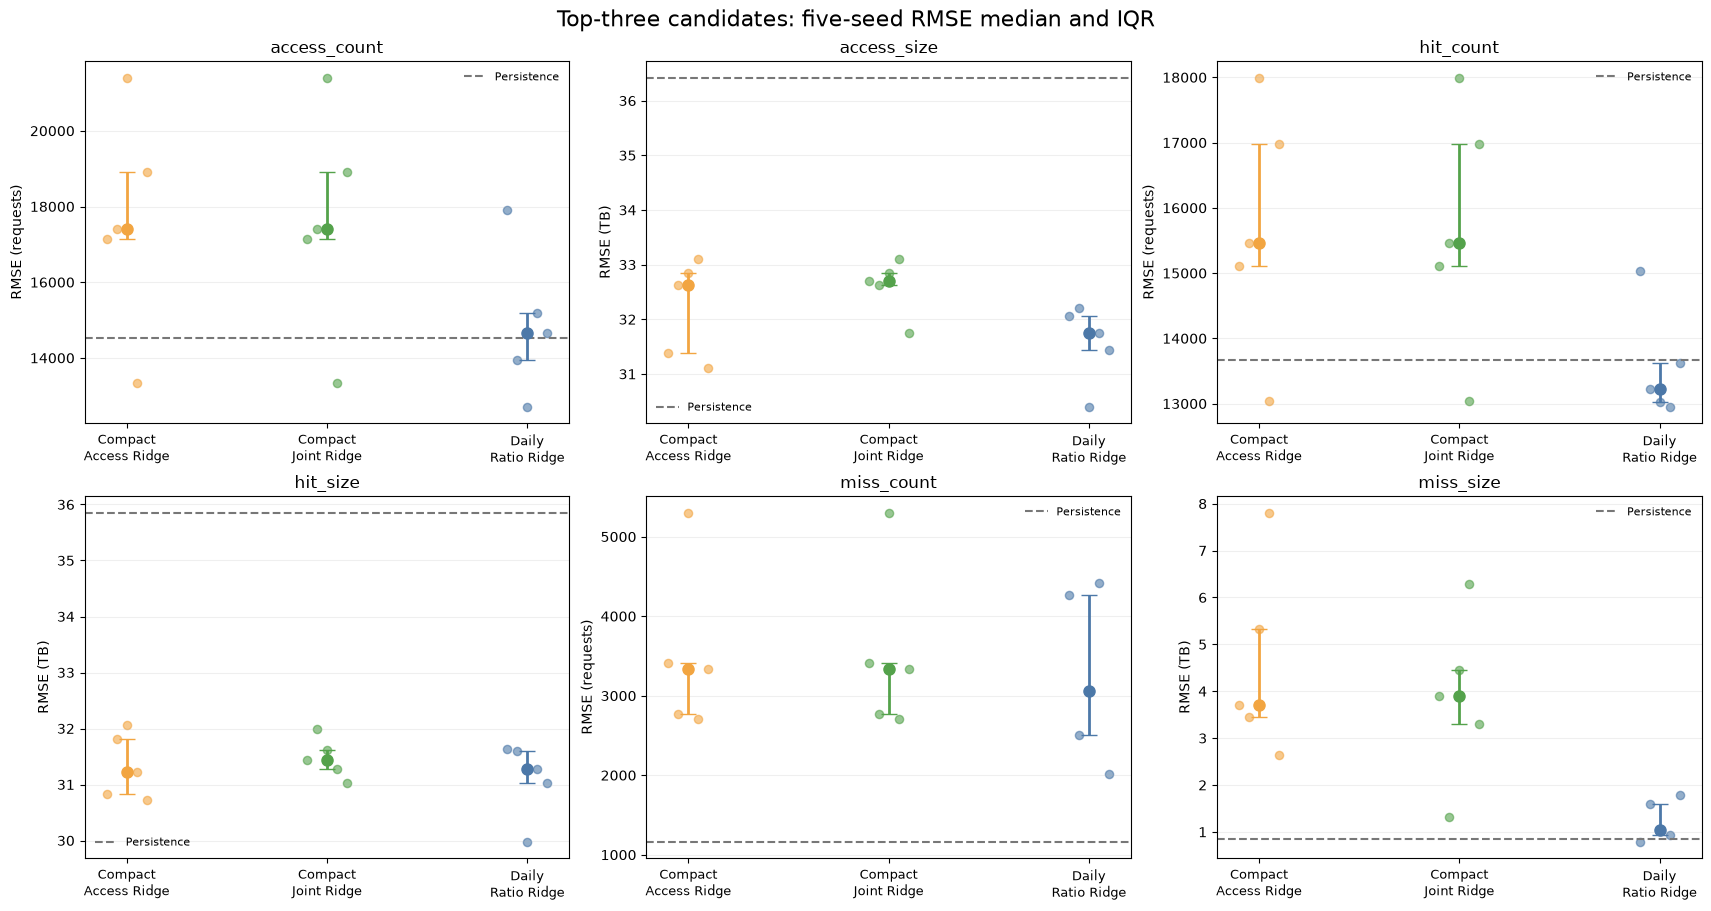

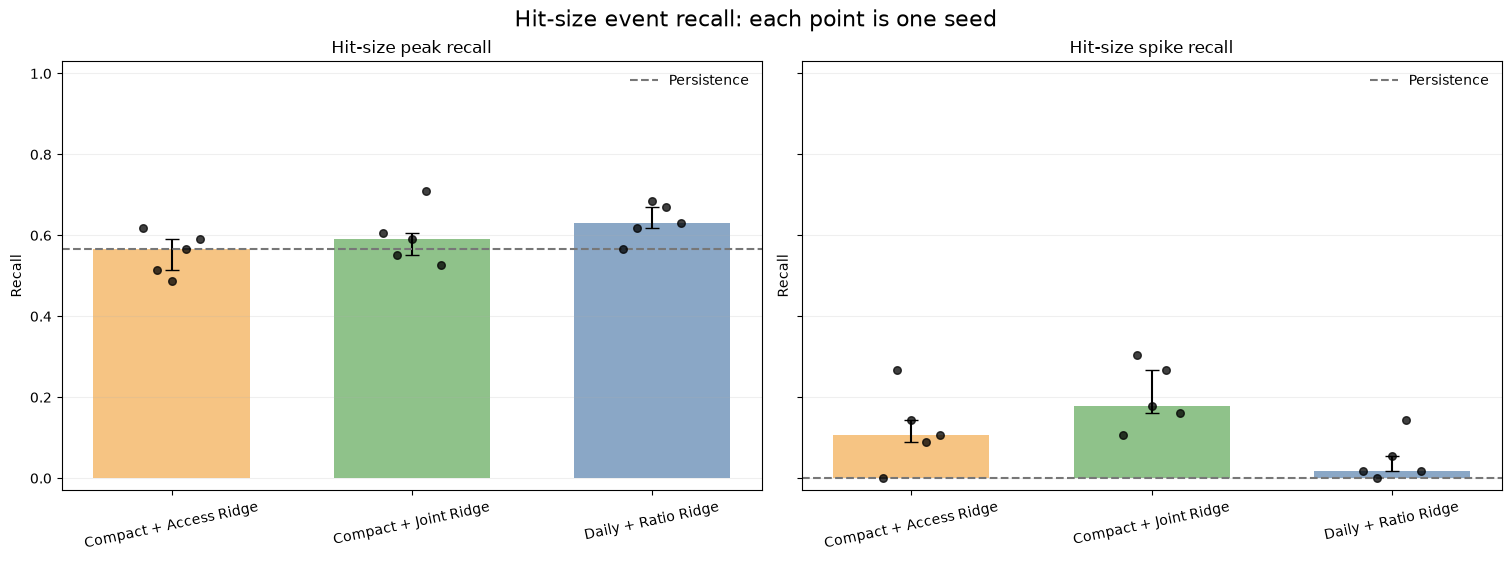

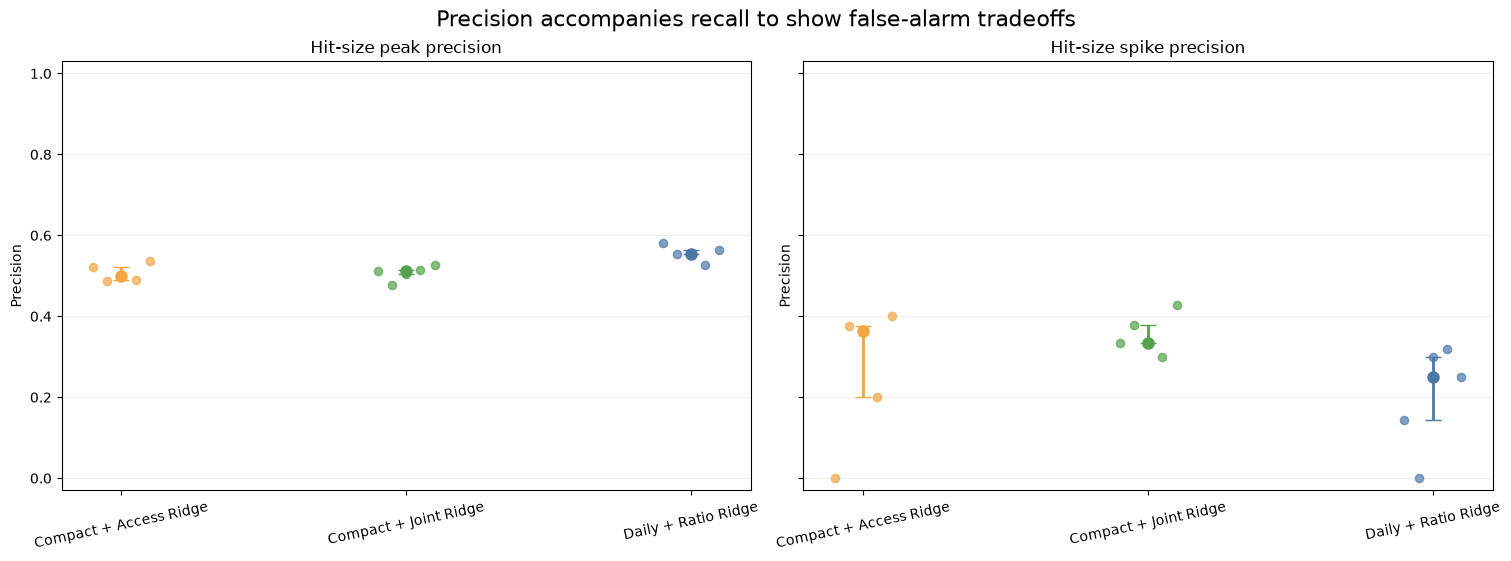

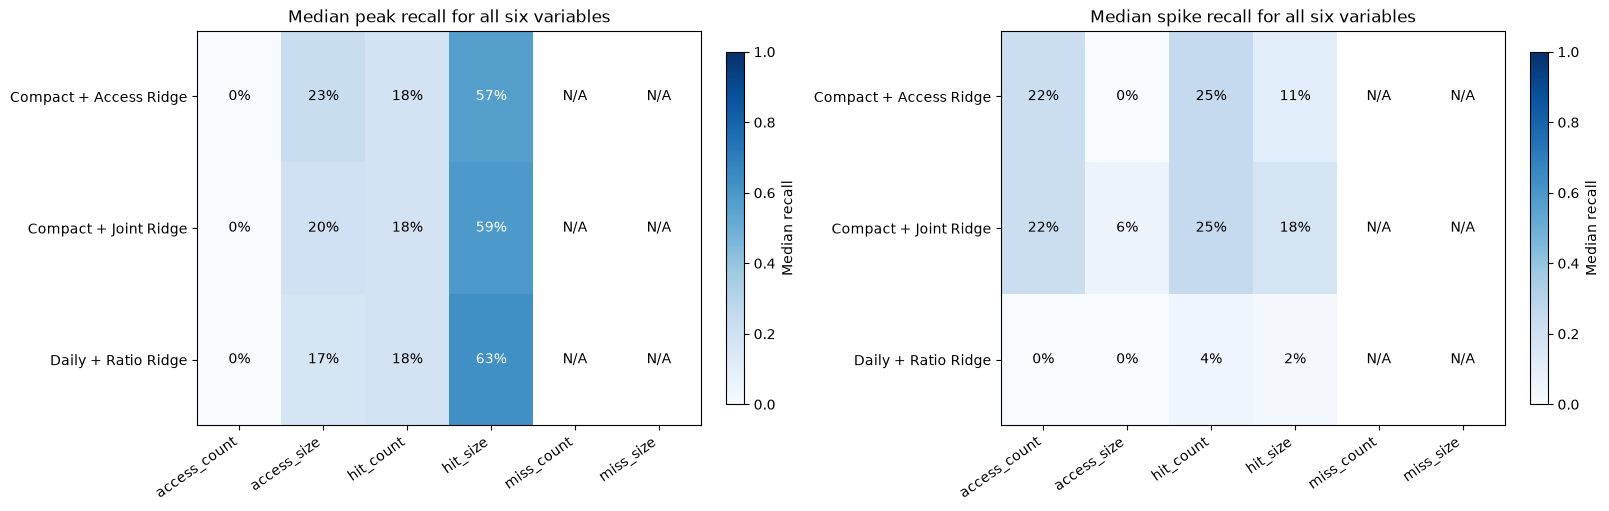

Saved robustness outputs: /Users/dengyingxin/Desktop/xcache/week10/results/whole_range_residual_ridge/top3_seed_robustness


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

robust_plot_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'week10' / 'Sammy_TCN_261111.ipynb').exists()), None)
if robust_plot_root is None:
    raise FileNotFoundError('Run inside the xcache project.')
robust_plot_dir = robust_plot_root / 'week10' / 'results' / 'whole_range_residual_ridge' / 'top3_seed_robustness'
plot_seed_metrics = pd.read_csv(robust_plot_dir / 'all_seed_test_metrics.csv')
plot_seed_events = pd.read_csv(robust_plot_dir / 'all_seed_six_variable_event_metrics.csv')
plot_persistence = pd.read_csv(robust_plot_dir / 'persistence_test_metrics.csv').iloc[0]
plot_persistence_events = pd.read_csv(robust_plot_dir / 'persistence_six_variable_events.csv')
plot_event_summary = pd.read_csv(robust_plot_dir / 'six_variable_event_median_iqr.csv')
plot_manifest = json.loads((robust_plot_dir / 'frozen_shortlist.json').read_text())
plot_candidates = [row['model'] for row in plot_manifest['candidates']]
plot_variables = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
short_names = {
    'compact_intraday: access Ridge': 'Compact + Access Ridge',
    'compact_intraday: joint Ridge': 'Compact + Joint Ridge',
    'daily_base: ratio Ridge': 'Daily + Ratio Ridge',
    'compact_intraday: TCN': 'Compact TCN',
    'daily_base: TCN': 'Daily TCN'}
candidate_colors = ['#f2a541', '#54a24b', '#4c78a8']

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for axis, variable in zip(axes.flat, plot_variables):
    for i, (model_name, color) in enumerate(zip(plot_candidates, candidate_colors)):
        values = plot_seed_metrics.loc[plot_seed_metrics.model == model_name, f'{variable}_rmse'].to_numpy()
        q25, med, q75 = np.quantile(values, [.25, .5, .75])
        axis.errorbar(i, med, yerr=[[med - q25], [q75 - med]], fmt='o',
                      color=color, capsize=6, markersize=8, linewidth=2)
        axis.scatter(i + np.linspace(-.10, .10, len(values)), values,
                     color=color, alpha=.6, s=35)
    axis.axhline(float(plot_persistence[f'{variable}_rmse']), color='#777777',
                 linestyle='--', label='Persistence')
    axis.set_xticks(range(len(plot_candidates)),
                    [short_names[name].replace(' + ', '\n') for name in plot_candidates], fontsize=9)
    axis.set_title(variable)
    axis.set_ylabel('RMSE (requests)' if 'count' in variable else 'RMSE (TB)')
    axis.grid(axis='y', alpha=.2)
    axis.legend(frameon=False, fontsize=8)
fig.suptitle('Top-three candidates: five-seed RMSE median and IQR', fontsize=16)
fig.savefig(robust_plot_dir / 'six_variable_rmse_five_seed_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True, constrained_layout=True)
for axis, event in zip(axes, ['peak', 'spike']):
    for i, (model_name, color) in enumerate(zip(plot_candidates, candidate_colors)):
        rows = plot_seed_events[(plot_seed_events.model == model_name)
                                & (plot_seed_events.variable == 'hit_size')
                                & (plot_seed_events.event == event)]
        values = rows.recall.to_numpy()
        q25, med, q75 = np.nanquantile(values, [.25, .5, .75])
        axis.bar(i, med, color=color, alpha=.65, width=.65)
        axis.errorbar(i, med, yerr=[[med - q25], [q75 - med]], color='black', capsize=5)
        axis.scatter(i + np.linspace(-.12, .12, len(values)), values,
                     color='black', s=30, alpha=.75, zorder=3)
    persistence_recall = float(plot_persistence_events[
        (plot_persistence_events.variable == 'hit_size')
        & (plot_persistence_events.event == event)].iloc[0].recall)
    axis.axhline(persistence_recall, linestyle='--', color='#777777', label='Persistence')
    axis.set_xticks(range(len(plot_candidates)), [short_names[name] for name in plot_candidates], rotation=12)
    axis.set(title=f'Hit-size {event} recall', ylim=(-.03, 1.03), ylabel='Recall')
    axis.legend(frameon=False)
    axis.grid(axis='y', alpha=.2)
fig.suptitle('Hit-size event recall: each point is one seed', fontsize=16)
fig.savefig(robust_plot_dir / 'hit_size_peak_spike_recall_five_seeds.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True, constrained_layout=True)
for axis, event in zip(axes, ['peak', 'spike']):
    for i, (model_name, color) in enumerate(zip(plot_candidates, candidate_colors)):
        values = plot_seed_events.loc[
            (plot_seed_events.model == model_name) & (plot_seed_events.variable == 'hit_size')
            & (plot_seed_events.event == event), 'precision'].to_numpy()
        q25, med, q75 = np.nanquantile(values, [.25, .5, .75])
        axis.errorbar(i, med, yerr=[[med - q25], [q75 - med]], color=color,
                      marker='o', capsize=6, markersize=8, linewidth=2)
        axis.scatter(i + np.linspace(-.1, .1, len(values)), values, color=color, alpha=.7, s=35)
    axis.set_xticks(range(len(plot_candidates)), [short_names[name] for name in plot_candidates], rotation=12)
    axis.set(title=f'Hit-size {event} precision', ylim=(-.03, 1.03), ylabel='Precision')
    axis.grid(axis='y', alpha=.2)
fig.suptitle('Precision accompanies recall to show false-alarm tradeoffs', fontsize=16)
fig.savefig(robust_plot_dir / 'hit_size_peak_spike_precision_five_seeds.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for axis, event in zip(axes, ['peak', 'spike']):
    table = plot_event_summary[
        plot_event_summary.model.isin(plot_candidates) & (plot_event_summary.event == event)
    ].pivot(index='model', columns='variable', values='recall_median').reindex(
        index=plot_candidates, columns=plot_variables)
    values = table.to_numpy()
    heat = axis.imshow(values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    axis.set_xticks(range(len(plot_variables)), plot_variables, rotation=35, ha='right')
    axis.set_yticks(range(len(plot_candidates)), [short_names[name] for name in plot_candidates])
    axis.set_title(f'Median {event} recall for all six variables')
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]
            axis.text(j, i, f'{value:.0%}' if np.isfinite(value) else 'N/A',
                      ha='center', va='center', color='white' if value > .55 else 'black', fontsize=10)
    fig.colorbar(heat, ax=axis, label='Median recall', fraction=.035)
fig.savefig(robust_plot_dir / 'six_variable_peak_spike_recall_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved robustness outputs:', robust_plot_dir)